In [176]:
import itertools
from ast import literal_eval
import os

import numpy as np
import pandas as pd
from pandas.api.types import CategoricalDtype

from scipy.integrate import trapezoid
from scipy.interpolate import interp1d
from scipy.stats import linregress, binned_statistic
from scipy.constants import Avogadro
from scipy.special import logsumexp
from scipy.optimize import minimize_scalar

from tqdm import tqdm

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

import seaborn as sns

from bussilab import wham
import MDAnalysis as mda

from mg_sampling import PROJECT_DIR
from mg_sampling.constants import RT
from mg_sampling.tools import read_plumed, read_plumed_fes, range_to_edges, edges_to_range, finitemin, finitemax, read_wsv, demux, block_bootstrap, bayesian_bootstrap, bootstrap
from mg_sampling.bias import bias_fn
from mg_sampling.density.align import reorder_residue_atoms
from mg_sampling.density.grid import Grid, SparseGrid
from mg_sampling.density.utils import indices_to_mask, voxels_around
from mg_sampling.density.plot import plot_map_slice

os.makedirs('figures', exist_ok=True)

sns.set_style("whitegrid")


plt.rcParams.update({
    'font.size': 8.0, 
    'figure.constrained_layout.use': True,
})

cm = 1 / 2.54  # inches

simlabels = {
    'plain_md_7ez0_mMg_tip3p': "μMg (MD)",
    'plain_md_7ez0_nMg_tip3p': "nMg (MD)",
    'plain_md_7ez0_nMg_tip3p_soft': "nMg (MD-soft)",
    'plain_md_7ez0_noion_nMg_tip3p': "nMg-novo (MD)",
    'replex_7ez0_mMg_tip3p': "μMg (REx)",
    'replex_7ez0_noion_mMg_tip3p': "μMg-novo (REx)",
    'plain_md_7ez0_nomg_mMg_tip3p': "no-Mg (MD)",
}

simcolors = {
    'plain_md_7ez0_mMg_tip3p': "gray",
    'plain_md_7ez0_nMg_tip3p': "mediumpurple",
    'plain_md_7ez0_nMg_tip3p_soft': "royalblue",
    'plain_md_7ez0_noion_nMg_tip3p': "mediumseagreen",
    'plain_md_7ez0_nomg_mMg_tip3p': "skyblue",
    'replex_7ez0_mMg_tip3p': "firebrick",
    'replex_7ez0_noion_mMg_tip3p': "tomato",
}

labelcolors = {
    v: simcolors[k] for k, v in simlabels.items()
}

ioncolors = {
    'NA': 'darkorchid',
    'MG': 'darkgreen',
    'CL': 'greenyellow',
}

ionlabels = {
    'NA': r'$\mathrm{Na^{+}}$',
    'MG': r'$\mathrm{Mg^{2\!+}}$',
    'CL': r'$\mathrm{Cl^{-}}$',
    'ztot': r'$Z_\mathrm{tot}$',
}

# Discard equilibration [ns]
simstart = {
    'plain_md_7ez0_mMg_tip3p': 150,
    'plain_md_7ez0_nMg_tip3p': 150,
    'plain_md_7ez0_nMg_tip3p_soft': 150,
    'plain_md_7ez0_noion_nMg_tip3p': 150,
    'plain_md_7ez0_nomg_mMg_tip3p': 100,
    'replex_7ez0_mMg_tip3p': 50,
    'replex_7ez0_noion_mMg_tip3p': 50,
}

# Set this to True to (re)compute expensive stuff
compute = False

# simselection = [
#     'plain_md_7ez0_mMg_tip3p',
#     'plain_md_7ez0_nMg_tip3p',
#     'plain_md_7ez0_nMg_tip3p_soft',
#     'plain_md_7ez0_nomg_mMg_tip3p',
#     'replex_7ez0_mMg_tip3p',  
# ]
# suffix = '_talk'
simselection = [
    'plain_md_7ez0_mMg_tip3p',
    'plain_md_7ez0_nMg_tip3p',
    'plain_md_7ez0_noion_nMg_tip3p',
    'plain_md_7ez0_nMg_tip3p_soft',
    'plain_md_7ez0_nomg_mMg_tip3p',
    'replex_7ez0_mMg_tip3p',
    'replex_7ez0_noion_mMg_tip3p',
]
suffix = ''

roman = "i ii iii iv v vi vii viii ix x xi xii xiii xiv xv xvi xvii xviii xix xx".split()

### Metadynamics

Full FES

In [220]:
path = PROJECT_DIR / 'metad/op_mMg_tip3p'

Unbound: [     0 143630   1240  21480 138770 144680 140890 139370  24860  91260]
Outer: [ 76440 175270 131560  72500 160280  46200 122000 155850 156090   7200]
Transition: [ 71180  86200  87160 153380  65890 115950  12760 175720  77640  28440]
Inner: [123770 147660 122230 190400  64780  68180  59380   4920 196050  11000]
Other mono: [126680 126120 128680 127610  80050  79170 125980 126670 125070 126060]
Other bi: [ 27710  81990 167830  78070 168030 181010 181600 167590  27560 182050]


/tmp/ipykernel_2949/734052376.py:30: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


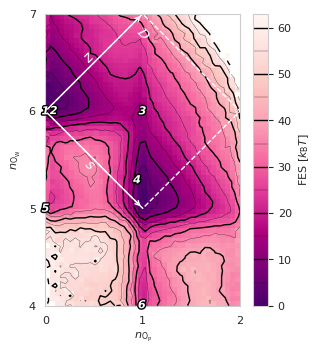

In [221]:
import matplotlib.patheffects as PathEffects

def plot_metad_fes(path, ax):
    colvar = read_plumed(f'{path}/COLVAR')
    bins = np.linspace(0, 2, 41), np.linspace(4, 7, 61)

    bias = colvar['metad.bias']  # kJ/mol
    weights = np.exp(bias/RT)

    # Remove nop == 0
    x, y = colvar['nop'], colvar['now']
    weights[x <= 0] = 0

    # Frames for rendering
    def get_frame(*d):
        frames = np.argsort(np.linalg.norm(np.stack(d), axis=0))
        return frames[frames % 10 == 0][:10]
    print("Unbound:", get_frame(x > 0, y - 6))
    print("Outer:", get_frame(x == 0, y - 6))
    print("Transition:", get_frame(x - 1, y - 6))
    print("Inner:", get_frame(x - 1, y - 5))
    print("Other mono:", get_frame(x - 0, y - 5))
    print("Other bi:", get_frame(x - 1, y - 4))

    for i, t in enumerate([24860, 76440, 71180, 147660, 80050, 27710]):
        txt = ax.text(x[t], y[t], i+1, color='white', fontweight='bold', fontstyle='italic', zorder=10, va='center', ha='center')
        txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='k')])

    ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
    fes = -np.log(ρ_avg)
    fes -= finitemin(fes)

    extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
    levels = np.arange(0, finitemax(fes), 5)

    im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
    cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
    cbar = plt.colorbar(im)
    cbar.add_lines(cf)
    cbar.set_label("FES [$k_\mathrm{B}T$]")

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(False)
    ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)
    ax.annotate("", xy=(1, 5), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
    ax.annotate("", xy=(1, 7), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
    ax.text(0.5, 5.5, r'$s$', rotation=-45, color='white', size=10, va='top', ha='center', rotation_mode='anchor')
    ax.text(0.5, 6.5, r'$z$', rotation=45, color='white', size=10, va='bottom', ha='center', rotation_mode='anchor')
    ax.text(1, 6.9, r'$\mathcal{D}$', rotation=-45, color='white', size=10, va='top', ha='left', rotation_mode='anchor')


    ax.set_xlabel("$n_\mathrm{O_P}$")
    ax.set_ylabel("$n_\mathrm{O_W}$")

fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm), layout="compressed")
plot_metad_fes(path, ax)

fig.savefig('figures/metad_fes.pdf')

With bias.

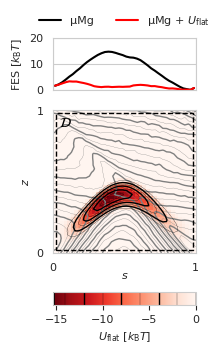

In [224]:
fig, (ax2, ax1, cax) = plt.subplots(nrows=3, height_ratios=[4, 12, 1], figsize=(5.4*cm, 8.7*cm))
ax2.sharex(ax1)
ax2.tick_params(labelbottom=False)

colvar = read_plumed(f'{path}/static.COLVAR')
params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

X_edges = np.linspace(0, 1, 41)
Y_edges = np.linspace(0, 1, 41)
bins = (X_edges, Y_edges)
X_range = edges_to_range(X_edges)
Y_range = edges_to_range(Y_edges)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x = colvar['nop']
y = colvar['now']
X = (colvar['nop'] - colvar['now'] + 6) / 2
Y = (colvar['nop'] + colvar['now'] - 6) / 2
weights[X <= 0] = 0
weights[X > 2] = 0
weights[Y <= 0] = 0
weights[Y > 2] = 0

ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 2)

#im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax1.contour(fes.T, colors=['gray'], linewidths=[1, 0.2], extent=extent, levels=levels)

# Show bias
XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
u = bias_fn((XX + YY), YY*2 - (XX + YY) + 6, *params) / RT
im = ax1.imshow(u.T, extent=extent, origin='lower', cmap='Reds_r')
cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
cf = ax1.contour(u.T, colors=['black'], linewidths=[1, 0.2], linestyles=['solid'], extent=extent, levels=-levels[::-1])
cbar.add_lines(cf)
cbar.set_label("$U_\mathrm{flat}$ [$k_\mathrm{B}T$]")
ε = 0.02
ax1.plot([ε, 1-ε, 1-ε, ε, ε], [ε, ε, 1-ε, 1-ε, ε], color='black', linestyle='dashed', linewidth=1)
ax1.text(2*ε, 1-2*ε, r"$\mathcal{D}$", color='black', size=10, va='top', ha='left')

ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.tick_params(labelbottom=True)
ax1.set_box_aspect(1)
ax1.set_xlabel("$s$", labelpad=-1)
ax1.set_ylabel("$z$")
ax1.grid(False)

# Block analysis for error on FES projection
def get_F_X(data):
    X, Y, weights = np.unstack(data, axis=-1)
    weights = weights / weights.sum()
    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    ρ_X = trapezoid(ρ_avg, X_range, axis=1)
    F_X = -np.log(ρ_X)
    F_X -= finitemin(F_X)
    return F_X

data = np.stack([X, Y, weights], axis=-1)
ax2.plot(X_range, get_F_X(data), color='black', label='μMg')
res = block_bootstrap(data, statistic=get_F_X, n_blocks=8)
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='black')

# Bias weighted
weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
data = np.stack([X, Y, weights], axis=-1)
res = block_bootstrap(np.stack([X, Y, weights], axis=-1), statistic=get_F_X, n_blocks=8)
ax2.plot(X_range, get_F_X(data), color='red', label='μMg + $U_\mathrm{flat}$')
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='red')

#ax2.set_xlabel("$s$", labelpad=1)
ax2.set_ylabel("FES [$k_\mathrm{B}T$]")
ax2.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)
ax2.set_ylim(0, 20)
ax2.set_xlim(0, 1)


fig.savefig('figures/bias_barrier.pdf')


Unbound: [178280  36580  82730  79840 161150  83700 161440   7360   9300 123260]
Outer: [  3970 155290 176500  34440  80460 174500 167310 132590 172850 173620]
Transition: [ 63860 154020 113760  31630  56580  77030   3290  43910 114860 177680]
Mono: [  1680 194410  63900   4880  67970 186950  97230 175670 170800 184990]
Other mono [180550 180620 181610  90810  90210 181450 181570 180230  11280 180030]
Transition Bi: [ 68790 155690  48930 107080  48990 108090 149710 196080  50420  69340]
Bidentate: [108780 105430 108820 152200 152150 198960 156350  68650 152230 109450]
Other clamp: [10770 40120 10780 89590 41650 92380 42520 94630 89550 10800]


/tmp/ipykernel_2949/4026510573.py:34: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


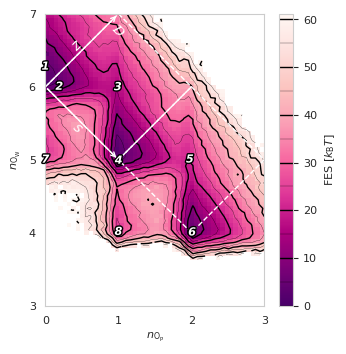

In [225]:
path = PROJECT_DIR / 'metad/triuridine/op_mMg_tip3p'

fig, ax = plt.subplots(figsize=(8.7*cm, 8.7*cm), layout="compressed")

colvar = read_plumed(f'{path}/COLVAR')
bins = np.linspace(0, 3, 51), np.linspace(3, 7, 71)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x, y = colvar['nop'], colvar['now']
weights[x <= 0] = 0

# Frames for rendering
def get_frame(*d):
    frames = np.argsort(np.linalg.norm(np.stack(d), axis=0))
    return frames[frames % 10 == 0][:10]
print("Unbound:", get_frame(x > 0, y - 6))
print("Outer:", get_frame(x == 0, y - 6))
print("Transition:", get_frame(x - 1, y - 6))
print("Mono:", get_frame(x - 1, y - 5))
print("Other mono", get_frame(x - 0, y - 5))
print("Transition Bi:", get_frame(x - 2, y - 5))
print("Bidentate:", get_frame(x - 2, y - 4))
print("Other clamp:", get_frame(x - 1, y - 4))

for i, t in enumerate([37000, 80460, 154020, 4880, 155690, 152200, 180550, 10770]):
    txt = ax.text(x[t], y[t], i+1, color='white', fontweight='bold', fontstyle='italic', zorder=10, ha='center', va='center')
    txt.set_path_effects([PathEffects.withStroke(linewidth=2, foreground='k')])


ρ_avg, x_edges, y_edges = np.histogram2d(x, y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*x_edges[[0, -1]], *y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 5)

im = ax.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax.contour(fes.T, colors=['black'], linewidths=[1, 0.2], extent=extent, levels=levels)
cbar = plt.colorbar(im)
cbar.add_lines(cf)
cbar.set_label("FES [$k_\mathrm{B}T$]")

ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(False)
ax.plot([0, 1, 2, 1, 0], [6, 7, 6, 5, 6], color='white', linestyle='dashed', linewidth=1)
ax.plot([1, 2, 3, 2, 1], [5, 6, 5, 4, 5], color='white', linestyle='dashed', linewidth=1)
ax.annotate("", xy=(1, 5), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(1, 7), xytext=(0, 6), color='white', zorder=20, arrowprops=dict(arrowstyle="->"))
ax.text(0.5, 5.5, r'$s$', rotation=-45, color='white', size=10, va='top', ha='center', rotation_mode='anchor')
ax.text(0.5, 6.5, r'$z$', rotation=45, color='white', size=10, va='bottom', ha='center', rotation_mode='anchor')
ax.text(1, 6.9, r'$\mathcal{D}$', rotation=-45, color='white', size=10, va='top', ha='left', rotation_mode='anchor')


ax.set_xlabel("$n_\mathrm{O_P}$")
ax.set_ylabel("$n_\mathrm{O_W}$")

fig.savefig('figures/triuridine_metad_fes.pdf')

/tmp/ipykernel_2949/2156478543.py:27: RuntimeWarning: divide by zero encountered in log
  fes = -np.log(ρ_avg)


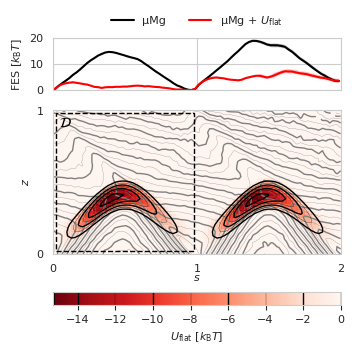

In [218]:
fig, (ax2, ax1, cax) = plt.subplots(nrows=3, height_ratios=[4, 12, 1], figsize=(8.7*cm, 8.7*cm))
ax2.sharex(ax1)
ax2.tick_params(labelbottom=False)
colvar = read_plumed(f'{path}/static.COLVAR')
params = read_wsv(f'{path}/bias_params.wsv').iloc[0]

X_edges = np.linspace(0, 2, 81)
Y_edges = np.linspace(0, 1, 41)
bins = (X_edges, Y_edges)
X_range = edges_to_range(X_edges)
Y_range = edges_to_range(Y_edges)

bias = colvar['metad.bias']  # kJ/mol
weights = np.exp(bias/RT)

# Remove nop == 0
x = colvar['nop']
y = colvar['now']
X = (colvar['nop'] - colvar['now'] + 6) / 2
Y = (colvar['nop'] + colvar['now'] - 6) / 2
weights[X <= 0] = 0
weights[X > 4] = 0
weights[Y <= 0] = 0
weights[Y > 2] = 0

ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
fes = -np.log(ρ_avg)
fes -= finitemin(fes)

extent = [*X_edges[[0, -1]], *Y_edges[[0, -1]]]
levels = np.arange(0, finitemax(fes), 2)

#im = ax1.imshow(fes.T, extent=extent, origin='lower', aspect=1, cmap='RdPu_r')
cf = ax1.contour(fes.T, colors=['gray'], linewidths=[1, 0.2], extent=extent, levels=levels)

# Show bias
XX, YY = np.meshgrid(X_range, Y_range, indexing='ij')
u = bias_fn((XX + YY), YY*2 - (XX + YY) + 6, *params) / RT
im = ax1.imshow(u.T, extent=extent, origin='lower', cmap='Reds_r')
cbar = fig.colorbar(im, cax=cax, orientation='horizontal')
cf = ax1.contour(u.T, colors=['black'], linewidths=[1, 0.2], linestyles=['solid'], extent=extent, levels=-levels[::-1])
cbar.add_lines(cf)
cbar.set_label("$U_\mathrm{flat}$ [$k_\mathrm{B}T$]")
ε = 0.02
ax1.plot([ε, 1-ε, 1-ε, ε, ε], [ε, ε, 1-ε, 1-ε, ε], color='black', linestyle='dashed', linewidth=1)
ax1.text(2*ε, 1-2*ε, r"$\mathcal{D}$", color='black', size=10, va='top', ha='left')

ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))
ax1.tick_params(labelbottom=True)
ax1.set_xlabel("$s$", labelpad=-1)
ax1.set_ylabel("$z$")
ax1.grid(False)

# Block analysis for error on FES projection
def get_F_X(data):
    X, Y, weights = np.unstack(data, axis=-1)
    weights = weights / weights.sum()
    ρ_avg, _, _ = np.histogram2d(X, Y, bins=bins, density=True, weights=weights)
    ρ_X = trapezoid(ρ_avg, Y_range, axis=1)
    F_X = -np.log(ρ_X)
    F_X -= finitemin(F_X)
    return F_X

data = np.stack([X, Y, weights], axis=-1)
ax2.plot(X_range, get_F_X(data), color='black', label='μMg')
res = block_bootstrap(data, statistic=get_F_X, n_blocks=8)
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='black')

# Bias weighted
weights = weights * np.exp(-bias_fn(x, y, *params)/RT)
data = np.stack([X, Y, weights], axis=-1)
res = block_bootstrap(np.stack([X, Y, weights], axis=-1), statistic=get_F_X, n_blocks=8)
ax2.plot(X_range, get_F_X(data), color='red', label='μMg + $U_\mathrm{flat}$')
ax2.fill_between(X_range, res.confidence_interval.low, res.confidence_interval.high, alpha=0.3, facecolor='red')

#ax2.set_xlabel("$s$", labelpad=1)
ax2.set_ylabel("FES [$k_\mathrm{B}T$]")
ax2.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)
ax2.set_ylim(0, 20)
ax2.set_xlim(0, 2)


fig.savefig('figures/triuridine_bias_barrier.pdf')


In [2]:
def to_states(x, low=0, high=1):
    state = np.digitize(x, (low, high))
    s0 = state[0]
    for i, s in enumerate(state):
        if s == 1:
            state[i] = s0
        elif s != s0:
            s0 = s
    return state / 2


### Effect of bias on binding affinity

Bound state including the barrier: $s > 0$

In [3]:
scalings = np.array([0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2])

data = []
for scaling in scalings:
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR').assign(scaling=scaling)
    colvar['s'] = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    data.append(colvar)
df = pd.concat(data)

bias = (df['cv.tot'].to_numpy()[:, None] * scalings) / RT
w = wham.wham(bias)
df['logW'] = w.logW
df['bound'] = df['s'] > 0


In [4]:
# Empirical
p_bound = df.groupby('scaling')['bound'].mean()
ΔG_bind = -RT * np.log(p_bound/(1-p_bound))

# Wham
bias = (df['cv.tot'].to_numpy() * scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_wham = -RT * np.log(p_bound_wham / (1 - p_bound_wham))

# Wham
new_scalings = np.linspace(0, 1.2, 25)
bias = (df['cv.tot'].to_numpy() * new_scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_wham_ext = -RT * np.log(p_bound_wham / (1 - p_bound_wham))


Excluding the barrier: $s \le 0$ and $s > 0.8$

In [5]:
# Empirical
df['bound_strict'] = df['s'] > 0.8
p_bound = df.groupby('scaling')['bound_strict'].mean()
p_unbound = 1 - df.groupby('scaling')['bound'].mean()
ΔG_bind_strict = -RT * np.log(p_bound/p_unbound)

# Wham
bias = (df['cv.tot'].to_numpy() * scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound_strict'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
p_unbound_wham = 1 - np.average(
    df['bound'].to_numpy() * np.ones_like(scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_strict_wham = -RT * np.log(p_bound_wham / p_unbound_wham)

# Wham
bias = (df['cv.tot'].to_numpy() * new_scalings[:, None]) / RT
p_bound_wham = np.average(
    df['bound_strict'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
p_unbound_wham = 1 - np.average(
    df['bound'].to_numpy() * np.ones_like(new_scalings)[:, None],
    weights=np.exp(df['logW'].to_numpy() - bias),
    axis=1,
)
ΔG_bind_strict_wham_ext = -RT * np.log(p_bound_wham / p_unbound_wham)

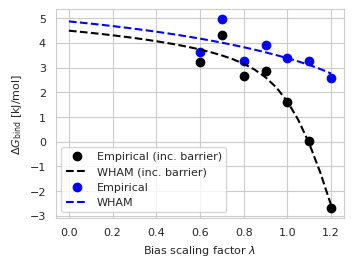

In [6]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

ax.scatter(ΔG_bind.index, ΔG_bind, color='black', label='Empirical (inc. barrier)')
ax.plot(new_scalings, ΔG_bind_wham_ext, color='black', ls='dashed', label='WHAM (inc. barrier)')
ax.scatter(ΔG_bind_strict.index, ΔG_bind_strict, color='blue', label='Empirical')
ax.plot(new_scalings, ΔG_bind_strict_wham_ext, color='blue', ls='dashed', label='WHAM')
ax.set_xlabel("Bias scaling factor $λ$")
ax.set_ylabel("$ΔG_\mathrm{bind}$ [kJ/mol]")
ax.legend(loc='lower left')
fig.savefig("figures/dGbind_bias.pdf")

### λ-wise MLE fit

In [7]:
data = []
for scaling in scalings:
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR')
    t_range = colvar['time'] / 1000
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    states = to_states(y, low=0, high=0.8)
    # Find transition times
    times = t_range[1:][states[:-1] != states[1:]]
    Δtimes = np.diff(times)
    assert states[0] == 0
    # Since states[0] should be 0 (unbound), first Δtime is 2->0 (unbinding)
    Δtimes_BA = Δtimes[::2]
    Δtimes_AB = Δtimes[1::2]

    # Maximum likelihood estimate of rate (exponential decay)
    def MLE_rate(times):
        k = (len(times) - 1) / np.sum(times)
        # Approximated 95% confidence interval
        k_low, k_high = k * (1 - 1.96 / np.sqrt(len(times))), k * (1 + 1.96 / np.sqrt(len(times)))
        return k, (k_low, k_high)

    vBA, (vBA_low, vBA_high) = MLE_rate(Δtimes_BA)
    vAB, (vAB_low, vAB_high) = MLE_rate(Δtimes_AB)

    bias = colvar['bias.bias']
    weights = np.exp(bias / RT)
    kish_ratio = np.sum(weights)**2 / np.sum(weights**2) / len(weights)    

    data.append({
        'scaling': scaling,
        'vAB': vAB,
        'vAB_low': vAB_low,
        'vAB_high': vAB_high,
        'vBA': vBA,
        'vBA_low': vBA_low,
        'vBA_high': vBA_high,
        'kish_ratio': kish_ratio,
    })
df = pd.DataFrame(data)
df

,scaling,vAB,vAB_low,vAB_high,vBA,vBA_low,vBA_high,kish_ratio
0,0.6,0.049422,0.025205,0.073639,0.210334,0.107271,0.313398,0.966305
1,0.7,0.076312,0.046979,0.105646,0.511972,0.318855,0.705089,0.966553
2,0.8,0.295507,0.234791,0.356223,0.991944,0.789246,1.194643,0.921084
3,0.9,0.661922,0.572607,0.751236,2.584361,2.235648,2.933074,0.893789
4,1.0,1.628873,1.481766,1.775980,4.278289,3.891908,4.664670,0.789342
5,1.1,3.044016,2.826013,3.262019,4.895297,4.544945,5.245649,0.599930
6,1.2,4.560364,4.233765,4.886962,3.184916,2.956975,3.412858,0.308849


v0_on =  1.74E-04 ns⁻¹
v0_off =  1.56E-03 ns⁻¹


/tmp/ipykernel_1497/1037871365.py:41: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


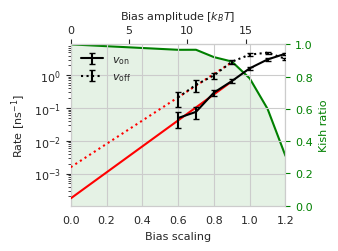

In [8]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
E = read_wsv(PROJECT_DIR / f'metad/op_mMg_tip3p/bias_params.wsv').iloc[0]['E'] / RT
ax.errorbar(df['scaling'], df['vAB'], yerr=(df['vAB'] - df['vAB_low'], df['vAB_high'] - df['vAB']), label=r'$v_\mathrm{on}$', color='black', zorder=10, capsize=2)

result = linregress(df.iloc[0:4]['scaling'], np.log(df.iloc[0:4]['vAB']))
v0_on = np.exp(result.intercept)

λ_range = np.linspace(0, 0.9, 2)
ax.plot(λ_range, np.exp(result.slope * λ_range + result.intercept), color='red', zorder=5)
print("v0_on = ", f'{v0_on:.2E} ns⁻¹')


ax.errorbar(df['scaling'], df['vBA'], yerr=(df['vBA'] - df['vBA_low'], df['vBA_high'] - df['vBA']), label=r'$v_\mathrm{off}$', color='black', linestyle='dotted', zorder=10, capsize=2)

result = linregress(df.iloc[0:4]['scaling'], np.log(df.iloc[0:4]['vBA']))
v0_off = np.exp(result.intercept)

λ_range = np.linspace(0, 0.9, 2)
ax.plot(λ_range, np.exp(result.slope * λ_range + result.intercept), color='red', ls='dotted', zorder=5)
print("v0_off = ", f'{v0_off:.2E} ns⁻¹')

ax.set_yscale('log')
ax.legend(frameon=False)
ax.set_xlabel("Bias scaling")
ax.set_xlim(0, df['scaling'].max())
ax.set_ylabel("Rate [ns$^{-1}$]")

secax = ax.secondary_xaxis('top', functions=(lambda x: E * x, lambda x: x / E))
secax.set_xlabel("Bias amplitude [$k_BT$]")

ax2 = ax.twinx()
ax2.grid(False)
ax2.yaxis.set_tick_params(labelcolor='green', color='green',
                         direction='out', which='major')
ax2.plot([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', color='green')
ax2.fill_between([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', facecolor='green', alpha=0.1)
ax2.set_ylim(0, 1)
ax2.set_zorder(-1)
ax2.set_ylabel("Kish ratio", color='green')
ax.patch.set_visible(False)
plt.tight_layout()
fig.savefig("figures/bias_kinetic_rates.pdf")

### Global MLE including ΔG estimation

$$
k(λ) = k_0e^{βλΔE^\ddagger}
$$
$$
k⁺(λ) = k(λ)e^{-β\frac{ΔG(λ)}{2}} = k_0e^{βλΔE^\ddagger}e^{-β\frac{ΔG(λ)}{2}} \\
k⁻(λ) = k(λ)e^{β\frac{ΔG(λ)}{2}} = k_0e^{βλΔE^\ddagger}e^{β\frac{ΔG(λ)}{2}}
$$
$$
p^±(t^±; k_0, ΔE^\ddagger, λ) = k^±(λ)e^{-k^±(λ)t^±}
$$


Log-likelihood for observation $t^±$
$$
\ell^±(k_0, ΔE^\ddagger, λ; t^±) = \ln k^±(λ) - k^±(λ)t^± = \ln k_0 + βλΔE^\ddagger ∓ β\frac{ΔG(λ)}{2} -  k_0e^{βλΔE^\ddagger}e^{∓β\frac{ΔG(λ)}{2}}t^±
$$

Total log-likelihood
$$
\ell\left(k_0, ΔE^\ddagger; \left\{(λ_k, \{t⁺_{k,i}\}^{n⁺_k}, \{t⁻_{k,j}\}^{n⁻_k})\right\}^K\right) = \sum_k^K \left[N_k\left(\ln k_0 + βλ_kΔE^\ddagger\right) - k_0e^{βλ_kΔE^\ddagger}\left(\sum_i^{n⁺_k}e^{-β\frac{ΔG(λ_k)}{2}}t⁺_{k,i} + \sum_j^{n⁻_k}e^{β\frac{ΔG(λ_k)}{2}}t⁻_{k,j}\right)\right] + \mathrm{const}
$$

$$
\frac{\partial\ell}{\partial k_0}(k_0, ΔE^\ddagger; X) = \sum_k^K \left[\frac{N_k}{k_0} - e^{βλ_kΔE^\ddagger}S_k\right]
$$

$$
\frac{\partial\ell}{\partial ΔE^\ddagger}(k_0, ΔE^\ddagger; X) = \sum_k^K \left[βλ_kN_k - k_0βλ_ke^{βλ_kΔE^\ddagger}S_k\right]
$$

$$
\frac{\partial\ell}{\partial k_0}(k_0, ΔE^\ddagger; X) = 0 \iff k_0 =  \frac{\sum_k^K N_k}{\sum_k^K e^{βλ_kΔE^\ddagger}S_k}
$$

$$
\frac{\partial\ell}{\partial ΔE^\ddagger}(k_0, ΔE^\ddagger; X) = 0 \iff k_0 = \frac{\sum_k λ_kN_k}{\sum_k λ_ke^{βλ_kΔE^\ddagger}S_k}
$$

$$
\iff \frac{\sum_k λ_kN_k}{\sum_k^K N_k}= \frac{\sum_k λ_ke^{βλ_kΔE^\ddagger}S_k}{\sum_k^K e^{βλ_kΔE^\ddagger}S_k}
$$

In [9]:
n_scalings = 3
n_bootstrap = 200
n_blocks = 4

blocks = []
for scaling, ΔG in zip(scalings[:n_scalings+1], ΔG_bind_strict_wham[:n_scalings+1]):
    colvar = read_plumed(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}/COLVAR')
    t_range = colvar['time'] / 1000
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    states = to_states(y, low=0, high=0.9)
    # Find transition times
    times = t_range[1:][states[:-1] != states[1:]]
    Δtimes = np.diff(times)
    assert states[0] == 0
    # Since states[0] should be 0 (unbound), first Δtime is 2->0 (unbinding)
    Δtimes_AB = Δtimes[1::2]
    Δtimes_BA = Δtimes[::2]
    for ab, ba in zip(np.array_split(Δtimes_AB, n_blocks), np.array_split(Δtimes_BA, n_blocks)):
        blocks.append((scaling, ΔG, ab, ba))


In [10]:
# Parameter estimation on all observations
S_k = []
λ_k = []
N_k = []

for block in blocks:
    scaling, ΔG, ab, ba = block
    S_k.append((ab * np.exp(-0.5 * ΔG / RT)).sum() + (ba * np.exp(0.5 * ΔG / RT)).sum())
    λ_k.append(scaling)
    N_k.append(len(ab) + len(ba))

S_k = np.array(S_k)
λ_k = np.array(λ_k)
N_k = np.array(N_k)

C = N_k.sum() / (λ_k * N_k).sum()

def loss(ΔE):
    return ((S_k * np.exp(ΔE * λ_k / RT)).sum() / (λ_k * S_k * np.exp(ΔE * λ_k / RT)).sum() - C)**2

res = minimize_scalar(loss)
ΔE = res.x
k0 = N_k.sum() / (S_k * np.exp(λ_k * ΔE / RT)).sum()
k0_on = k0 * np.exp(-ΔG_bind_strict_wham_ext[0]/2/RT)
k0_off = k0 * np.exp(ΔG_bind_strict_wham_ext[0]/2/RT)

# Error estimation by bootstrap on blocks of observations
bootstrap_distribution = []

for _ in range(n_bootstrap):
    S_k = []
    λ_k = []
    N_k = []

    inds = np.random.choice(len(blocks), size=len(blocks))

    for i in inds:
        scaling, ΔG, ab, ba = blocks[i]
        S_k.append((ab * np.exp(-0.5 * ΔG / RT)).sum() + (ba * np.exp(0.5 * ΔG / RT)).sum())
        λ_k.append(scaling)
        N_k.append(len(ab) + len(ba))
    
    S_k = np.array(S_k)
    λ_k = np.array(λ_k)
    N_k = np.array(N_k)

    C = N_k.sum() / (λ_k * N_k).sum()

    def loss(ΔE):
        return ((S_k * np.exp(ΔE * λ_k / RT)).sum() / (λ_k * S_k * np.exp(ΔE * λ_k / RT)).sum() - C)**2

    res = minimize_scalar(loss)
    ΔE = res.x
    k0 = N_k.sum() / (S_k * np.exp(λ_k * ΔE / RT)).sum()
    k0_on = k0 * np.exp(-ΔG_bind_strict_wham_ext[0]/2/RT)
    k0_off = k0 * np.exp(ΔG_bind_strict_wham_ext[0]/2/RT)
    bootstrap_distribution.append((ΔE, k0, k0_on, k0_off))

ci = np.quantile(bootstrap_distribution, (0.025, 0.975), axis=0)

In [11]:
print("ΔE = ", f'{ΔE:.2E} ({ci[0,0]:.2E}-{ci[1,0]:.2E}) kJ/mol')
print("k0 = ", f'{k0:.2E} ({ci[0,1]:.2E}-{ci[1,1]:.2E}) ns⁻¹')
print("k0_on = ", f'{k0_on:.2E} ({ci[0,2]:.2E}-{ci[1,2]:.2E}) ns⁻¹')
print("k0_off = ", f'{k0_off:.2E} ({ci[0,3]:.2E}-{ci[1,3]:.2E}) ns⁻¹')


ΔE =  2.20E+01 (2.01E+01-2.40E+01) kJ/mol
k0 =  4.54E-04 (2.45E-04-8.91E-04) ns⁻¹
k0_on =  1.71E-04 (9.25E-05-3.36E-04) ns⁻¹
k0_off =  1.20E-03 (6.50E-04-2.36E-03) ns⁻¹


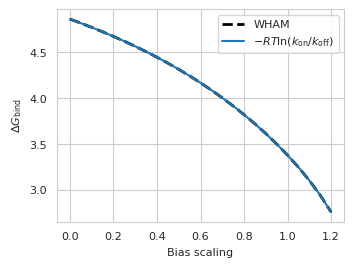

In [12]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

ax.plot(new_scalings, ΔG_bind_strict_wham_ext, label='WHAM', color='black', ls='dashed', lw=2)
ax.plot(new_scalings, -RT * np.log(
    (k0*np.exp(new_scalings * ΔE / RT) * np.exp(-0.5*ΔG_bind_strict_wham_ext/RT))
    / (k0*np.exp(new_scalings * ΔE / RT) * np.exp(0.5*ΔG_bind_strict_wham_ext/RT))
), label=r"$-RT\ln (k_\mathrm{on}/k_\mathrm{off})$")

ax.set_ylabel('$ΔG_\mathrm{bind}$')
ax.set_xlabel("Bias scaling")
ax.legend()
fig.savefig(f'figures/dGbind_kon_koff.pdf')

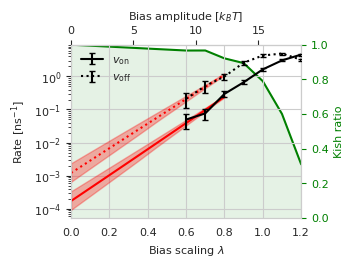

In [27]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

E = read_wsv(PROJECT_DIR / f'metad/op_mMg_tip3p/bias_params.wsv').iloc[0]['E'] / RT
ax.errorbar(df['scaling'], df['vAB'], yerr=(df['vAB'] - df['vAB_low'], df['vAB_high'] - df['vAB']), label=r'$v_\mathrm{on}$', color='black', zorder=10, capsize=2)
ax.errorbar(df['scaling'], df['vBA'], yerr=(df['vBA'] - df['vBA_low'], df['vBA_high'] - df['vBA']), label=r'$v_\mathrm{off}$', color='black', linestyle='dotted', zorder=10, capsize=2)

k_on_bs = []
k_off_bs = []
for _ΔE, _k0, _, _ in bootstrap_distribution:
    k_on_bs.append(_k0*np.exp(new_scalings * _ΔE / RT) * np.exp(-0.5*ΔG_bind_strict_wham_ext/RT))
    k_off_bs.append(_k0*np.exp(new_scalings * _ΔE / RT) * np.exp(0.5*ΔG_bind_strict_wham_ext/RT))

k_on = k0 * np.exp(new_scalings * ΔE / RT) * np.exp(-0.5 * ΔG_bind_strict_wham_ext / RT)
k_off = k0 * np.exp(new_scalings * ΔE / RT) * np.exp(0.5 * ΔG_bind_strict_wham_ext / RT)
k_on_p025, k_on_p975 = np.quantile(k_on_bs, (0.025, 0.975), axis=0)
k_off_p025, k_off_p975 = np.quantile(k_off_bs, (0.025, 0.975), axis=0)

mask = new_scalings <= scalings[n_scalings-1]

ax.fill_between(new_scalings[mask], k_on_p025[mask], k_on_p975[mask], color='red', alpha=0.3)
ax.fill_between(new_scalings[mask], k_off_p025[mask], k_off_p975[mask], color='red', alpha=0.3)

ax.plot(new_scalings[mask], k_on[mask], color='red')
ax.plot(new_scalings[mask], k_off[mask], color='red', ls='dotted')

ax.set_yscale('log')
ax.legend(frameon=False)
ax.set_xlabel("Bias scaling $λ$")
ax.set_xlim(0, df['scaling'].max())
ax.set_ylabel("Rate [ns$^{-1}$]")

secax = ax.secondary_xaxis('top', functions=(lambda x: E * x, lambda x: x / E))
secax.set_xlabel("Bias amplitude [$k_BT$]")

ax2 = ax.twinx()
ax2.grid(False)
ax2.yaxis.set_tick_params(labelcolor='green', color='green',
                         direction='out', which='major')
ax2.plot([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', color='green')
ax2.fill_between([0, *df['scaling']], [1, *df['kish_ratio']], label='Kish ratio', facecolor='green', alpha=0.1)
ax2.set_ylim(0, 1)
ax2.set_zorder(-1)
ax2.set_ylabel("Kish ratio", color='green')
ax.patch.set_visible(False)
fig.savefig(f"figures/bias_kinetic_rates_mle{suffix}.pdf")

In [33]:
i, = np.argwhere(np.isclose(new_scalings, 1))[0]
print("At λ = 1")
print("k0_on = ", f'{k_on[i]:.2E} ({k_on_p025[i]:.2E}-{k_on_p975[i]:.2E}) ns⁻¹')
print("k0_off = ", f'{k_off[i]:.2E} ({k_off_p025[i]:.2E}-{k_off_p975[i]:.2E}) ns⁻¹')


At λ = 1
k0_on =  1.54E+00 (1.40E+00-1.89E+00) ns⁻¹
k0_off =  5.96E+00 (5.41E+00-7.32E+00) ns⁻¹


In [16]:
def committor(x, low=0, high=1, bins=20):
    state = np.digitize(x, (low, high))  # 0 = A, 1 = in between, 2 = B
    # For each state whether it will end in A or B
    s0 = state[-1]
    for i, s in enumerate(state[::-1]):
        if s == 1:
            state[::-1][i] = s0
        elif s != s0:
            s0 = s
    # Probability of ending in B
    ends_in_B = (state == 2)
    statistic, bin_edges, _ = binned_statistic(x, ends_in_B, bins=bins)
    return edges_to_range(bin_edges), statistic

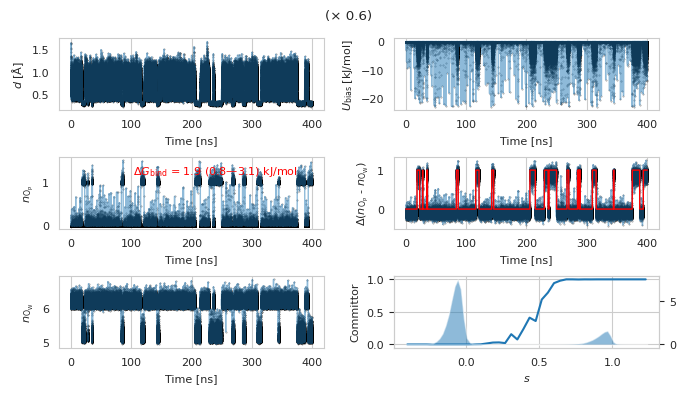

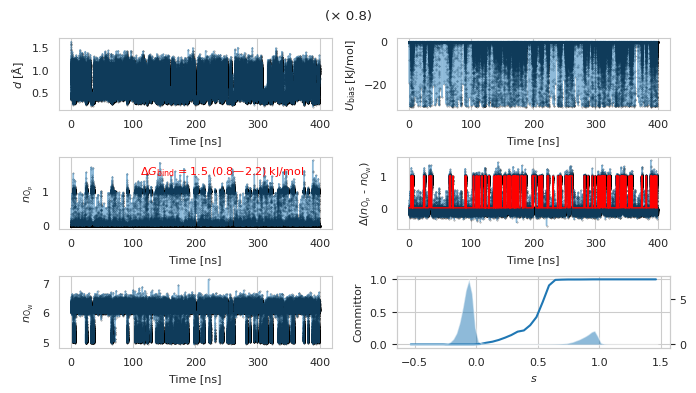

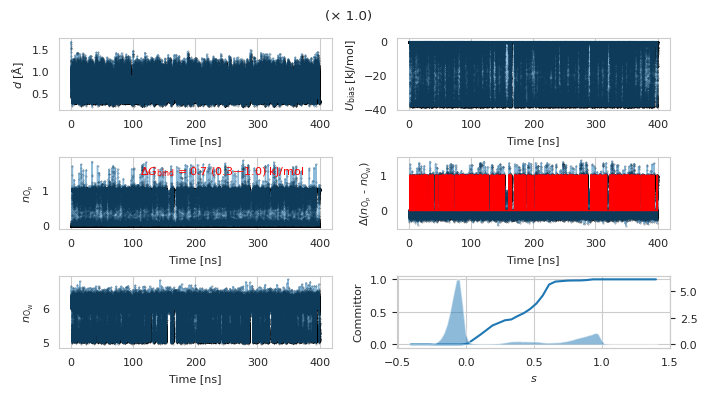

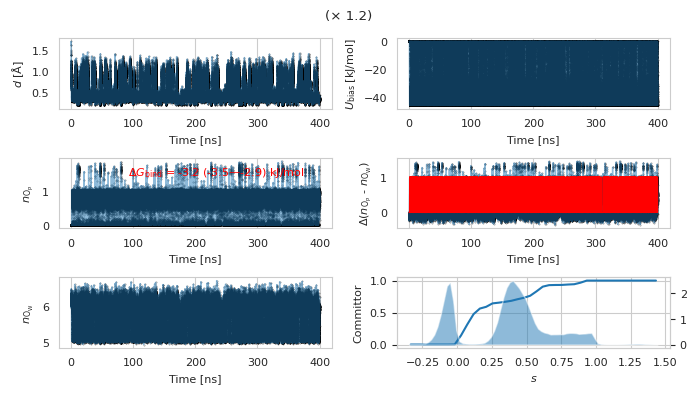

In [ ]:
def plot_bias_timeseries(path, axarr):
    colvar = read_plumed(f'{path}/COLVAR')
    t_range = colvar['time'] / 1000

    ax = axarr[0, 0]
    y = colvar['dop']
    ax.plot(t_range, y, lw=1, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=0.1, alpha=0.5, c='k', rasterized=True)
    ax.set_ylabel("$d$ [Å]")
    ax.grid(axis='y')
    ax.set_xlabel(r'Time [ns]')

    ax = axarr[1, 0]
    y = colvar['cv.nb-0'] * 1.039661
    is_bound = (y > 0)
    def get_ΔG(is_bound):
        p_bound = np.mean(is_bound)
        return -RT*np.log(p_bound/(1-p_bound))
    bs = block_bootstrap(is_bound, statistic=get_ΔG, n_blocks=8)
    ΔGmean = get_ΔG(is_bound)
    ΔGerr = bs.confidence_interval
    ax.text(0.9, 0.9, f"$ΔG_\mathrm{{bind}}$ = {ΔGmean:.1f} ({ΔGerr.low:.1f}—{ΔGerr.high:.1f}) kJ/mol", transform=ax.transAxes, ha='right', va='top', color='red')
    ax.plot(t_range, y, lw=1, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=0.1, alpha=0.5, c='k', rasterized=True)
    ax.set_ylabel("$n_\mathrm{O_P}$")
    ax.grid(axis='y')
    ax.set_xlabel(r'Time [ns]')

    ax = axarr[2, 0]
    y = colvar['cv.nc-0'] * 1.039661
    ax.plot(t_range, y, lw=1, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=0.1, alpha=0.5, c='k', rasterized=True)
    ax.set_ylabel("$n_\mathrm{O_W}$")
    ax.grid(axis='y')
    ax.set_xlabel(r'Time [ns]')

    ax = axarr[0, 1]
    y = colvar['bias.bias']
    ax.plot(t_range, y, lw=1, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=0.1, alpha=0.5, c='k', rasterized=True)
    ax.set_ylabel("$U_\mathrm{flat}$ [kJ/mol]")
    ax.grid(axis='y')
    ax.set_xlabel(r'Time [ns]')

    ax = axarr[1, 1]
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    state = to_states(y, low=0, high=0.9)
    ax.plot(t_range, y, lw=1, alpha=0.5, rasterized=True)
    ax.scatter(t_range, y, s=0.1, alpha=0.5, c='k', rasterized=True)
    ax.set_ylabel("$\Delta (n_\mathrm{O_P}$ - $n_\mathrm{O_W})$")
    ax.grid(axis='y')
    ax.plot(t_range, state, color='red', lw=1)
    ax.set_xlabel(r'Time [ns]')

    ax = axarr[2, 1]
    y = (colvar['cv.nb-0'] * 1.039661 - colvar['cv.nc-0'] * 1.039661 + 6) / 2
    y_range, statistic = committor(y, low=0, high=0.9, bins=40)
    ax.plot(y_range, statistic)
    ax.set_xlabel("$s$")
    ax.set_ylabel("Committor")
    ρ_y, y_edges = np.histogram(y, bins=80, density=True)
    y_range = edges_to_range(y_edges)
    ax = ax.twinx()
    ax.grid(False)
    ax.fill_between(y_range, ρ_y, alpha=0.5)

    return axarr

scalings = [0.6, 0.8, 1.0, 1.2]
for scaling in scalings:
    fig, axarr = plt.subplots(nrows=3, ncols=2, figsize=(17.8*cm, 10*cm))
    plot_bias_timeseries(PROJECT_DIR / f'kinetics/op_mMg_tip3p/{scaling:.1f}', axarr)
    fig.suptitle(f"(× {scaling:.1f})")
    plt.tight_layout()
    fig.savefig(f"figures/bias_timeseries_{scaling:.1f}.pdf")

## Intron

Ion counts with time

In [35]:
# Load binding motif data
ions = ['NA', 'MG']
df = pd.DataFrame()

# Replex
method = 'replex'
systems = ['7ez0', '7ez0_noion']
ff = 'mMg_tip3p'
replicates = [0, 1]
repids = range(8)

for ion in ions:
    for sys in systems:
        for rep, i in itertools.product(replicates, repids):
            _df = pd.read_csv(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/{ion}_motifs.csv')
            _df = _df[['time', 'index', 'n_inner', 'n_outer']]
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=i)
            colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
            colvar['time'] = colvar['time'].astype(int)
            _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

# Plain MD
method = 'plain_md'
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for ion in ions:
    for sys, ff in itertools.product(systems, forcefields):
        for rep in replicates:
            path = PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}'
            if not path.exists():
                continue
            _df = pd.read_csv(PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/{ion}_motifs.csv')
            _df = _df[['time', 'index', 'n_inner', 'n_outer']]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=0)
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df['reptemp'] = 0
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

/tmp/ipykernel_1497/3362816810.py:38: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  _df = pd.read_csv(PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/{ion}_motifs.csv')


In [36]:
df

,time,index,n_inner,n_outer,ion,sim,system,replicate,repid,reptemp
0,0.0,269659,0,0,NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
1,0.0,269660,0,0,NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
2,0.0,269661,0,0,NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
3,0.0,269662,1,11,NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
4,0.0,269663,0,0,NA,replex_7ez0_mMg_tip3p,7ez0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
106973,600.0,269704,0,24,MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
106974,600.0,269705,0,0,MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
106975,600.0,269706,1,12,MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0
106976,600.0,269707,1,13,MG,plain_md_7ez0_noion_nMg_tip3p,7ez0_noion,7,0,0


Time evolution:

In [37]:
res = df.groupby(['ion', 'sim', 'system', 'replicate', 'repid', 'reptemp', 'time', 'n_inner']).size().unstack(fill_value=0).stack().reset_index(name='count')
res = res.query('n_inner > 0 and reptemp == 0').groupby(['ion', 'sim', 'system', 'replicate', 'time'])['count'].sum().reset_index(name='count').groupby(['ion', 'sim', 'system', 'time'])['count'].aggregate(['mean', 'sem'])
res

mean       sem
ion sim                         system     time                   
MG  plain_md_7ez0_mMg_tip3p     7ez0       0.0    20.500  0.188982
                                           1.0    20.250  0.250000
                                           2.0    20.125  0.226582
                                           3.0    20.125  0.226582
                                           4.0    20.250  0.250000
...                                                  ...       ...
NA  replex_7ez0_noion_mMg_tip3p 7ez0_noion 196.0  23.500  1.500000
                                           197.0  23.000  2.000000
                                           198.0  18.000  1.000000
                                           199.0  18.500  0.500000
                                           200.0  19.000  2.000000

[5612 rows x 2 columns]

KeyError: 'MG'

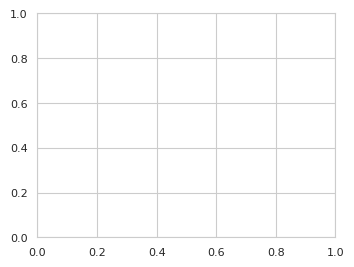

In [ ]:
n_inner_pdb = 14

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for (sim, group) in res.loc['MG'].groupby("sim"):
    if sim not in simselection:
        continue
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.3, color=simcolors[sim], edgecolor='none')
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel(f"Inner-bound {ionlabels['MG']}")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels)
ax.set_ylim(0, 120)
ax.set_xlim(0, 600)
ax.axhline(n_inner_pdb, ls='dashed', lw=1, color='silver')
ax.text(550, n_inner_pdb - 2, '7EZ0', style='italic', color='silver', ha='center', va='top')

plt.tight_layout()
fig.savefig(f'figures/inner_bound_mg_timeseries{suffix}.pdf')



/tmp/ipykernel_1497/2296408719.py:22: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


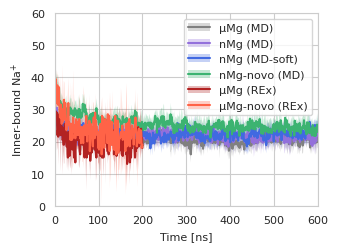

In [ ]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for (sim, group) in res.loc['NA'].groupby("sim"):
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.3, color=simcolors[sim], edgecolor='none')
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel(f"Inner-bound {ionlabels['NA']}")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels)
ax.set_ylim(0, 60)
ax.set_xlim(0, 600)

plt.tight_layout()
fig.savefig('figures/inner_bound_na_timeseries.pdf')

In [114]:
res = df.query('n_inner == 0 and n_outer > 0 and reptemp == 0').groupby(['ion', 'sim', 'system', 'replicate', 'repid', 'reptemp', 'time']).size().reset_index(name='count')
res = res.groupby(['ion', 'sim', 'system', 'time'])['count'].aggregate(['mean', 'sem'])

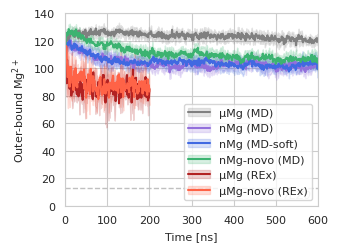

In [115]:
n_outer_pdb = 13

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for (sim, group) in res.loc['MG'].groupby("sim"):
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.2, color=simcolors[sim])
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel("Outer-bound Mg$^{2+}$")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels)
ax.set_ylim(0, 140)
ax.set_xlim(0, 600)
ax.axhline(n_outer_pdb, ls='dashed', lw=1, color='silver')
ax.text(550, n_outer_pdb - 2, '7EZ0', style='italic', color='silver', ha='center', va='top')

plt.tight_layout()
fig.savefig('figures/outer_bound_mg_timeseries.pdf')


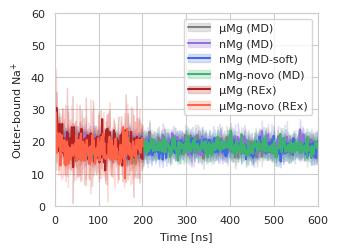

In [116]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

labels, handles = [], []
for (sim, group) in res.loc['NA'].groupby("sim"):
    x = group.index.get_level_values("time")
    y = group["mean"]
    err = group["sem"]
    
    lower = y - 1.96*err
    upper = y + 1.96*err
    line, = ax.plot(x, y, color=simcolors[sim])
    patch = ax.fill_between(x, lower, upper, alpha=0.2, color=simcolors[sim])
    labels.append(simlabels[sim])
    handles.append((line, patch))

ax.set_ylabel("Outer-bound Na$^{+}$")
ax.set_xlabel("Time [ns]")
ax.legend(handles, labels)
ax.set_ylim(0, 60)
ax.set_xlim(0, 600)

plt.tight_layout()
fig.savefig('figures/outer_bound_na_timeseries.pdf')

Bound/Outer/Bulk

In [48]:
res = pd.DataFrame({
    'inner': df.query('n_inner > 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
    'outer': df.query('n_inner == 0 and n_outer > 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
    'bulk': df.query('n_inner == 0 and n_outer == 0').groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time']).size(),
})

res['total'] = res['inner'] + res['outer'] + res['bulk']
res['start_time'] = res.index.get_level_values('sim').map(simstart)
res = res.query('time > start_time')[['bulk', 'outer', 'inner']]
res = res.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp']).aggregate(['mean', 'count'])
res = res.stack(level=0)
res.index.set_names('type', level=-1, inplace=True)
res

/tmp/ipykernel_636827/1025588410.py:11: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  res = res.stack(level=0)


mean  \
ion sim                         replicate repid reptemp type                
MG  plain_md_7ez0_mMg_tip3p     0         0     0       bulk    30.113333   
                                                        inner   30.180000   
                                                        outer  117.706667   
                                1         0     0       bulk    30.028889   
                                                        inner   24.015556   
...                                                                   ...   
NA  replex_7ez0_noion_mMg_tip3p 1         7     6       inner   20.416667   
                                                        outer   18.333333   
                                                7       bulk    77.714286   
                                                        inner   22.000000   
                                                        outer   21.285714   

                                                               count  
ion sim                         replicate repid reptemp type          
MG  plain_md_7ez0_mMg_tip3p     0         0     0       bulk     450  
                                                        inner    450  
                                                        outer    450  
                                1         0     0       bulk     450  
                                                        inner    450  
...                                                              ...  
NA  replex_7ez0_noion_mMg_tip3p 1         7     6       inner     12  
                                                        outer     12  
                                                7       bulk       7  
                                                        inner      7  
                                                        outer      7  

[1644 rows x 2 columns]

In [49]:
res = pd.DataFrame({
    'mean': res.groupby(['ion', 'sim', 'reptemp', 'type']).apply(lambda x: np.average(x['mean'], weights=x['count'])),
    'ci': res.groupby(['ion', 'sim', 'reptemp', 'type']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['count']).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

/tmp/ipykernel_636827/707980051.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_636827/707980051.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):


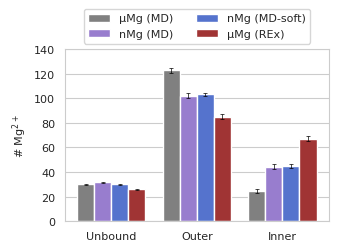

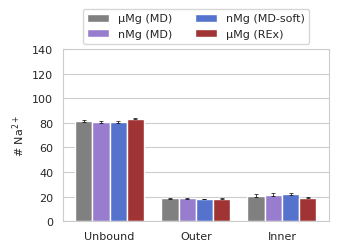

In [ ]:
for ion in ['MG', 'NA']:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))


    data = res.loc[ion, res.index.isin(simselection, level=1), 0, :].rename(index=simlabels).rename(index=dict(outer='Outer', inner='Inner', bulk='Unbound')).reset_index()
    data['sim'] = data['sim'].astype(CategoricalDtype(categories=simlabels.values(), ordered=True)).cat.remove_unused_categories()

    type_order = ['Unbound', 'Outer', 'Inner']
    data['type'] = data['type'].astype(CategoricalDtype(categories=type_order, ordered=True))
    data = data.sort_values(['type', 'sim'])

    ax = sns.barplot(
        data=data,
        x='type',
        y='mean',
        hue='sim',
        palette=labelcolors,
        ax=ax,
    )

    for i, (sim, group) in enumerate(data.groupby('sim')):
        container = ax.containers[i]
        x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
        yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
        ax.errorbar(
            x=x_coords,
            y=group['mean'],
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )
    plt.legend(ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))

    ax.set_ylabel(f"# {ionlabels[ion]}")
    ax.set_xlabel(None)
    ax.set_ylim(None, 140)
    plt.tight_layout()
    fig.savefig(f'figures/bound_{ion.lower()}_barplot{suffix}.pdf')


### Denticity

In [51]:
res = df.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'time', 'n_inner']).size().unstack(fill_value=0).stack().reset_index(name='count')
res['start_time'] = res['sim'].map(simstart)
res = res.query('time > start_time and n_inner > 0')
res = res.groupby(['ion', 'sim', 'replicate', 'repid', 'reptemp', 'n_inner'])['count'].agg(['mean', 'count'])
res = pd.DataFrame({
    'mean': res.groupby(['ion', 'sim', 'reptemp', 'n_inner']).apply(lambda x: np.average(x['mean'], weights=x['count'])),
    'ci': res.groupby(['ion', 'sim', 'reptemp', 'n_inner']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['count']).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

In [52]:
res

mean  \
ion sim                         reptemp n_inner              
MG  plain_md_7ez0_mMg_tip3p     0       1        13.657222   
                                        2         6.613056   
                                        3         2.796667   
                                        4         1.796389   
                                        5         0.010556   
...                                                    ...   
NA  replex_7ez0_noion_mMg_tip3p 7       8         0.006667   
                                        9         0.000000   
                                        10        0.000000   
                                        11        0.000000   
                                        12        0.000000   

                                                                                            ci  \
ion sim                         reptemp n_inner                                                  
MG  plain_md_7ez0_mMg_tip3p     0       1             (11.775617479224818, 15.598174256165034)   
                                        2               (5.882326513550631, 7.147706139457362)   
                                        3               (2.147676373229419, 3.454409900959418)   
                                        4             (1.4734048181281378, 2.0045964902815494)   
                                        5         (0.006408451143468958, 0.015296342178841033)   
...                                                                                        ...   
NA  replex_7ez0_noion_mMg_tip3p 7       8        (0.0014550482229013257, 0.021042099605038278)   
                                        9                                           (0.0, 0.0)   
                                        10                                          (0.0, 0.0)   
                                        11                                          (0.0, 0.0)   
                                        12                                          (0.0, 0.0)   

                                                      p025       p095  
ion sim                         reptemp n_inner                        
MG  plain_md_7ez0_mMg_tip3p     0       1        11.775617  15.598174  
                                        2         5.882327   7.147706  
                                        3         2.147676   3.454410  
                                        4         1.473405   2.004596  
                                        5         0.006408   0.015296  
...                                                    ...        ...  
NA  replex_7ez0_noion_mMg_tip3p 7       8         0.001455   0.021042  
                                        9         0.000000   0.000000  
                                        10        0.000000   0.000000  
                                        11        0.000000   0.000000  
                                        12        0.000000   0.000000  

[480 rows x 4 columns]

/tmp/ipykernel_636827/560765119.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_636827/560765119.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):


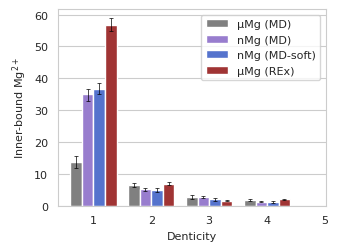

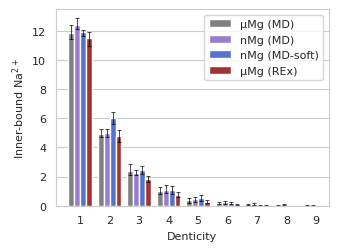

In [ ]:
for ion in ['MG', 'NA']:
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    data = res.query('mean > 0.01')
    data = data.loc[ion, data.index.isin(simselection, level=1), 0, :].rename(index=simlabels).reset_index()
    data['sim'] = data['sim'].astype(CategoricalDtype(categories=simlabels.values(), ordered=True)).cat.remove_unused_categories()

    ax = sns.barplot(
        data=data,
        x='n_inner',
        y='mean',
        hue='sim',
        palette=labelcolors,
        ax=ax,
    )

    for i, (sim, group) in enumerate(data.groupby('sim')):
        container = ax.containers[i]
        x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
        yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
        ax.errorbar(
            x=x_coords,
            y=group['mean'],
            yerr=yerr,
            ls='none',
            c='black',
            capsize=1.5,
            elinewidth=0.5,
            capthick=0.5,
        )
    ax.get_legend().set_title(None)

    ax.set_ylabel(f'Inner-bound {ionlabels[ion]}')
    ax.set_xlabel('Denticity')
    plt.tight_layout()
    fig.savefig(f'figures/bound_{ion.lower()}_denticity{suffix}.pdf')


### Residue distribution

In [46]:
# Load binding motif data
ions = ['NA', 'MG']
df = pd.DataFrame()

# Replex
method = 'replex'
systems = ['7ez0', '7ez0_noion']
ff = 'mMg_tip3p'
replicates = [0, 1]
repids = range(8)

for ion in ions:
    for sys in systems:
        for rep, i in itertools.product(replicates, repids):
            _df = pd.read_csv(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/{ion}_motifs.csv')
            _df = _df[['time', 'index', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames']]
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=i)
            colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/{ff}/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
            colvar['time'] = colvar['time'].astype(int)
            _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

# Plain MD
method = 'plain_md'
systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for ion in ions:
    for sys, ff in itertools.product(systems, forcefields):
        for rep in replicates:
            path = PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/rep{rep:02d}/{ion}_motifs.csv'
            if not path.exists():
                continue
            _df = pd.read_csv(path)
            _df = _df[['time', 'index', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames']]
            _df = _df.assign(ion=ion, sim=f"{method}_{sys}_{ff}", system=sys, replicate=rep, repid=0)
            _df = _df.loc[_df['time'].astype(int) % 1000 == 0]
            _df['reptemp'] = 0
            _df['time'] = _df['time'] / 1000  # ns

            df = pd.concat([df, _df])

/tmp/ipykernel_1497/399237615.py:38: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  _df = pd.read_csv(path)


In [47]:
x = df.loc[df['time'] > df['sim'].map(simstart)].copy()
x = x.query('reptemp == 0')
n_frames = x.groupby(['sim', 'replicate', 'repid'])['time'].nunique()
cols = [col for col in x.columns if col.startswith('inner')]
x = x.query("inner_indices != '[]'")
x[cols] = x[cols].map(literal_eval)
x = x.explode(cols)
x = x.query("inner_names == 'O2P' or inner_names == 'O1P'")
counts = x.groupby(['sim', 'replicate', 'repid', 'ion', 'inner_resids', 'inner_names']).size()

In [48]:
x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')
x['n_frames'] = n_frames
x['weights'] = x['n_frames'] / x.groupby(['sim', 'ion', 'inner_resids', 'inner_names'])['n_frames'].sum()
x['p'] = x['count'] / x['n_frames']

/tmp/ipykernel_1497/646398015.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')
/tmp/ipykernel_1497/646398015.py:1: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  x = counts.unstack('inner_names', fill_value=0).unstack('inner_resids', fill_value=0).unstack('ion', fill_value=0).stack().stack().stack().to_frame(name='count')


In [49]:
res = pd.DataFrame({
    'mean': x.groupby(['sim', 'ion', 'inner_resids', 'inner_names']).apply(lambda x: np.average(x['p'], weights=x['weights'])),
    'ci': x.groupby(['sim', 'ion', 'inner_resids', 'inner_names']).apply(lambda x: 
        bayesian_bootstrap(x['p'], np.average, weights=x['weights'], n_resamples=20).confidence_interval),
    })
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])

In [50]:
ref_7ez0 = pd.read_parquet(PROJECT_DIR / 'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet')
ref_7ez0 = ref_7ez0.explode(['inner_indices', 'inner_resnames', 'inner_resids', 'inner_names'])
ref_9cbu = pd.read_parquet(PROJECT_DIR / 'structures/9cbu/MG_motifs_summary.parquet')
ref_9cbu = ref_9cbu.explode(['inner_indices', 'inner_resnames', 'inner_resids', 'inner_names'])

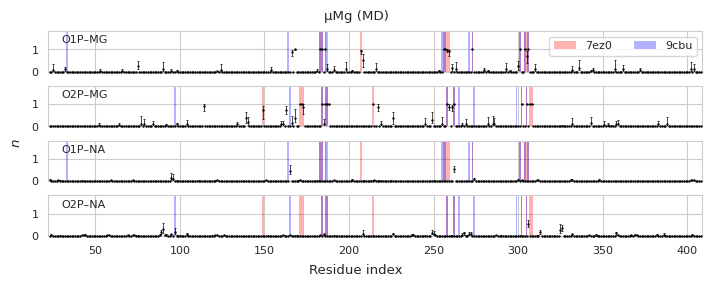

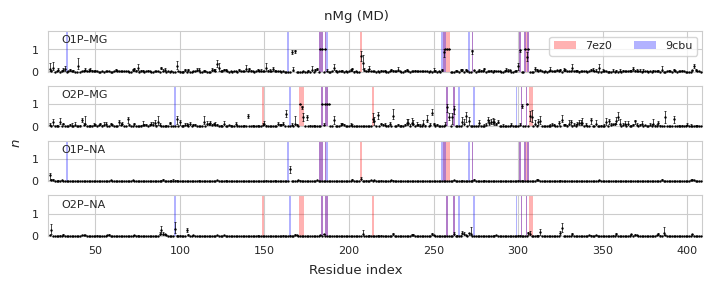

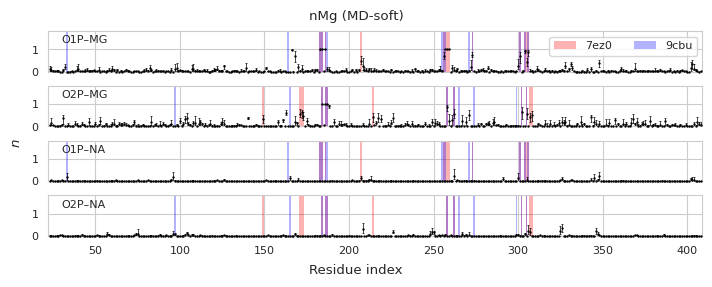

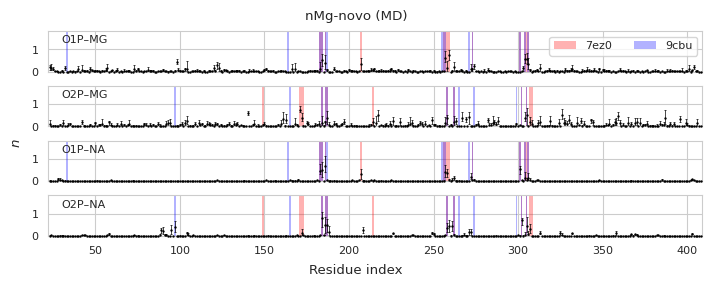

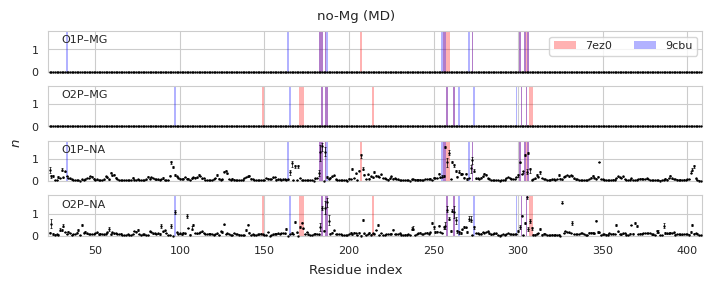

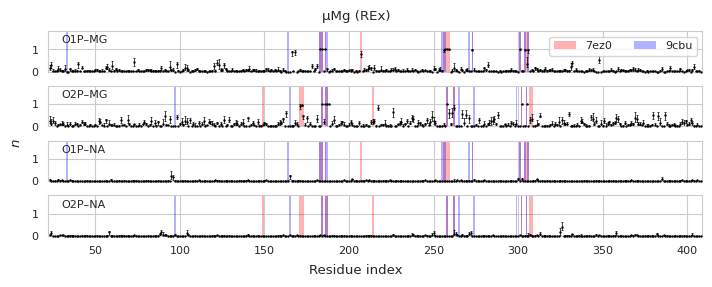

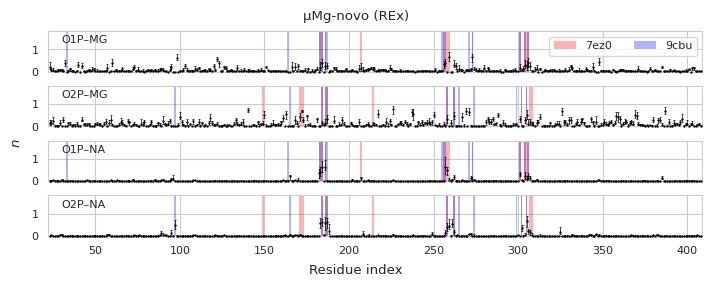

In [ ]:

for sim, group in res.groupby('sim'):
    fig, axarr = plt.subplots(nrows=4, figsize=(17.8*cm,7*cm), sharex=True, sharey=True)

    for ax, (ion, name) in zip(axarr, itertools.product(['MG', 'NA'], ['O1P', 'O2P'])):
        data = group.loc[sim, ion, :, name]
        yerr = ((data['mean'] - data['p025']).clip(0, None), (data['p095'] - data['mean']).clip(0, None))
        ax.errorbar(data.index, data['mean'], yerr=yerr, linestyle='none', marker='none', capsize=1, elinewidth=0.5, ecolor='black', capthick=0.5)
        
        ref_resids = ref_7ez0.query('inner_names == @name')['inner_resids']
        for i in ref_resids.values:
            h1 = ax.axvspan(i-0.5, i+0.5, facecolor='red', edgecolor='none', alpha=0.3)
        ref_resids = ref_9cbu.query('inner_names == @name')['inner_resids']
        for i in ref_resids.values:
            h2 = ax.axvspan(i-0.5, i+0.5, facecolor='blue', edgecolor='none', alpha=0.3)

        ax.scatter(data.index, data['mean'], marker='.', c='black', s=2, zorder=10, clip_on=False)
        ax.text(0.02, 0.9, f"{name}–{ion}", ha='left', va='top', transform=ax.transAxes)

    axarr[0].legend([h1, h2], ['7ez0', '9cbu'], ncol=2, loc='upper right')
    fig.suptitle(f"{simlabels[sim]}")
    fig.supylabel(r"Occupancy")
    fig.supxlabel(f"Residue index")
    
    plt.ylim(0, res['p095'].max())
    plt.xlim(data.index.min()-1, data.index.max()+1)
    plt.savefig(f"figures/sequence_bound_{sim}.pdf")
    

### RDFs

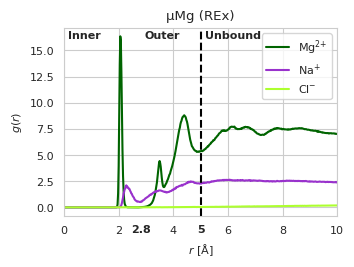

In [70]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))


for ion in ['MG', 'NA', 'CL']:
    rdf = np.loadtxt(PROJECT_DIR / f'replex/7ez0/mMg_tip3p/replicate0/demux/0_{ion}_RNA_rdf.xvg', comments=['#', '@'])
    ax.plot(rdf[:, 0]*10, rdf[:, 1], color=ioncolors[ion], label=ionlabels[ion])
    ax.set_xlim(0, 10)
ax.axvline(5, color='black', ls='dashed')
ax.annotate("Inner", xy=(0, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Outer", xy=(2.8, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Unbound", xy=(5, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("2.8", xy=(2.8, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')
ax.annotate("5", xy=(5, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')

ax.set_ylabel(r'$g(r)$')
ax.set_xlabel(r'$r$ [Å]')
ax.legend()
ax.set_title('μMg (REx)')
fig.savefig('figures/rdfs_mMg.pdf')

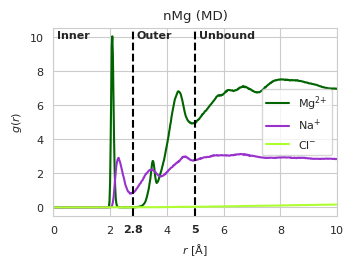

In [62]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

for ion in ['MG', 'NA', 'CL']:
    rdf = np.loadtxt(PROJECT_DIR / f'plain_md/7ez0/nMg_tip3p/replicate0/rep00/{ion}_RNA_rdf.xvg', comments=['#', '@'])
    ax.plot(rdf[:, 0]*10, rdf[:, 1], color=ioncolors[ion], label=ionlabels[ion])
    ax.set_xlim(0, 10)
ax.axvline(2.8, color='black', ls='dashed')
ax.axvline(5, color='black', ls='dashed')
ax.annotate("Inner", xy=(0, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Outer", xy=(2.8, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("Unbound", xy=(5, 1), xytext=(3, -2), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='left', fontweight='bold')
ax.annotate("2.8", xy=(2.8, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')
ax.annotate("5", xy=(5, 0), xytext=(0, -6), xycoords=('data', 'axes fraction'), textcoords='offset points', va='top', ha='center', fontweight='bold')

ax.set_ylabel(r'$g(r)$')
ax.set_xlabel(r'$r$ [Å]')
ax.legend()
ax.set_title('nMg (MD)')
fig.savefig('figures/rdfs_nMg.pdf')

### Occupation of sites

In [59]:
res.groupby(['sim', 'ion', 'inner_names'])['mean'].apply(lambda x: np.mean(x > 0.01))

sim                            ion  inner_names
plain_md_7ez0_mMg_tip3p        MG   O1P            0.129534
                                    O2P            0.150259
                               NA   O1P            0.746114
                                    O2P            0.329016
plain_md_7ez0_nMg_tip3p        MG   O1P            0.528497
                                    O2P            0.580311
                               NA   O1P            0.759067
                                    O2P            0.347150
plain_md_7ez0_nMg_tip3p_soft   MG   O1P            0.588083
                                    O2P            0.621762
                               NA   O1P            0.808290
                                    O2P            0.417098
plain_md_7ez0_noion_nMg_tip3p  MG   O1P            0.577720
                                    O2P            0.582902
                               NA   O1P            0.787565
                                    O2P            0

### Motif analysis

In [13]:
def atom_latex_name(s):
    return f"\mathrm{{{s[0]}}}_\mathrm{{{s[1:]}}}"

def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"${atom_latex_name(name)}^\mathrm{{{resname}{resid}}}$" for resname, resid, name in zip(resnames, resids, names))
    if x['stereo']:
        motif = x['stereo'] + "-" + motif
    return motif

def motif_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"{resname}{resid}{name}" for resname, resid, name in zip(resnames, resids, names))
    if mgrna:
        motif += '-' + mgrna
    return motif

def label_disjoint_sets(sets):
    """
    From a list of sets, find group membership such that
    non-disjoint sets belong to the same group.
    """
    from scipy.cluster.hierarchy import DisjointSet
    # Groupping by non-empty intersection
    # In: a list of sets {a, b, c}, {d, e}, {e, f}, {a}, {g, h}...
    # Out: a list of group id such as sets with non-null intersection belong to the same group
    #      0, 1, 1, 0, 2 ...
    # Algo: list elements a, b, c, d, e, f, g, ...
    #       assign different group ids
    #       for each pair of sets, if s1 & s2 != 0, set all elements of s1 | s2 to the leftmost id

    ds = DisjointSet()
    for s in sets:
        for x in s:
            ds.add(x)
            ds.merge(x, s[0])
    
    group_ids = [ds._parents[s[0]] for s in sets]
    _, group_ids = np.unique(group_ids, return_inverse=True)

    return group_ids

def summarize_motifs(df):
    df['motif'] = df.apply(motif_name, axis=1).astype('category')

    # Create a unique id for each block of data for error estimate
    df['block'], _ = pd.factorize(df[['replicate', 'repid']].apply(tuple, axis='columns'))

    count = df.groupby(['block', 'time', 'motif'], observed=True).size()
    count = count.unstack('motif', fill_value=0)

    p_block = count.groupby('block').mean()
    block_weight = count.groupby('block').size().rename('block_weight')
    block_weight /= block_weight.sum()

    p = p_block.mul(block_weight, axis='index').sum().rename('p')

    # Error estimate: bayesian bootstrap with blocks
    ci = p_block.apply(
        lambda x: tuple(map(float, bayesian_bootstrap(x, np.average, weights=block_weight).confidence_interval))
    ).transpose().set_axis(['p_low', 'p_high'], axis='columns')

    n_block_obs = (p_block > 0).sum().rename('n_block_obs')

    res = pd.concat([p, ci, n_block_obs], axis='columns')

    res = res.join(
        df.drop_duplicates(subset='motif', keep='first').set_index('motif')[['n_inner', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames', 'stereo', 'mgrna']]
    )

    mg_indices = df.groupby('motif', observed=True)['index'].agg(lambda x: list(set(x))).rename('mg_indices')
    res = res.join(mg_indices)

    return res


In [101]:
if compute:
    # Replex
    t_start = 50000  # ps
    t_end = 200000 # ps
    systems = ['7ez0', '7ez0_noion']
    replicates = [0, 1]
    repids = range(8)

    for sys in systems:
        df = pd.DataFrame()
        for rep, i in itertools.product(replicates, repids):
            _df = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=i)
            colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
            colvar['time'] = colvar['time'].astype(int)
            _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
            _df = _df.query('time >= @t_start and time < @t_end')
            df = pd.concat([df, _df])

        # Multiplexing and analysis
        for λ in repids:
            res = summarize_motifs(df.query('reptemp == @λ').copy())
            res.to_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda{λ}.parquet')
    
    # Plain MD
    t_start = 150000  # ps
    t_end = 500000 # ps
    systems = ['7ez0', '7ez0_noion']
    forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
    replicates = range(8)

    for sys, ff in itertools.product(systems, forcefields):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/rep{rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                break
            _df = _df.query('time >= @t_start and time < @t_end')
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet')


In [ ]:
# Before equilibration
compute = True
if compute:
    systems = ['7ez0']
    forcefields = ['mMg_tip3p']
    replicates = range(8)

    for sys, ff in itertools.product(systems, forcefields):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/rep{rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                break
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_summary.parquet')

# After equilibration
compute = True
if compute:
    systems = ['7ez0']
    forcefields = ['mMg_tip3p']
    replicates = range(8)

    for sys, ff in itertools.product(systems, forcefields):
        df = pd.DataFrame()
        for rep in replicates:
            try:
                _df = pd.read_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/rep{rep:02d}/MG_motifs_equil.parquet').assign(replicate=rep, repid=0)
            except FileNotFoundError as e:
                break
            df = pd.concat([df, _df])
        else:
            res = summarize_motifs(df)
            res.to_parquet(PROJECT_DIR / f'structures/{sys}/{ff}/MG_motifs_equil_summary.parquet')

In [14]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/replicate0/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}')
    except FileNotFoundError:
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_equil_summary.parquet').assign(sim=f'7ez0_equil')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
res = res.query('n_inner > 1')
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
# res['motif_group'] = label_disjoint_sets(res['inner_labels'])
# res['group_max_p'] = res.groupby('motif_group')['p'].transform('max')
res['motif_max_p'] = res.groupby('motif')['p'].transform('max')
res = res.query('motif_max_p > 0.01')
motif_latex = res.set_index('motif').apply(motif_latex_name, axis=1).drop_duplicates()
# p = res.set_index(['group_max_p', 'motif_group', 'motif_max_p', 'motif', 'sim'])['p']
p = res.set_index(['motif_max_p', 'motif', 'sim'])['p']

In [15]:
p

motif_max_p  motif                                     sim                  
0.015964     A104O2P,U267O2P-cis-2Oph                  replex_7ez0_mMg_tip3p    0.000333
0.370667     A122O1P,A123O1P-cis-2Oph                  replex_7ez0_mMg_tip3p    0.249667
1.000000     A172O2P,A173O2P-cis-2Oph                  replex_7ez0_mMg_tip3p    0.440333
             A183O1P,A184O2P,A186O2P-fac-3Oph          replex_7ez0_mMg_tip3p    0.998000
             A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph  replex_7ez0_mMg_tip3p    0.998667
                                                                                  ...   
             A261N7,A265O2P-cis-OphNb                  9cbu                     1.000000
             A301O1P,A302O2P-cis-2Oph                  9cbu                     1.000000
             A304O1P,A306O1P-cis-2Oph                  9cbu                     1.000000
             C165O2P,U167O2'-cis-OphOr                 9cbu                     1.000000
             G257O1P,U258O2P,U305

In [124]:
p = p.unstack('sim').sort_index(ascending=False).droplevel([0]).rename(columns=simlabels)

In [125]:
print(p.reset_index().to_latex(na_rep='–', float_format="{:0.2f}".format))

\begin{tabular}{llrrrrrrrrr}
\toprule
sim & motif & 7ez0 & 7ez0_equil & 9cbu & μMg (MD) & nMg (MD) & nMg (MD-soft) & nMg-novo (MD) & μMg (REx) & μMg-novo (REx) \\
\midrule
0 & U307O2P,A308O2P-cis-2Oph & 1.00 & 1.00 & – & 1.00 & 0.44 & 0.46 & 0.17 & 0.24 & 0.10 \\
1 & U258O1P,U259O2P,A261O2P-fac-3Oph & – & 1.00 & – & 0.83 & 0.38 & 0.22 & – & 0.60 & – \\
2 & G257O1P,U258O2P,U305O2P-fac-3Oph & – & – & 1.00 & 0.25 & 0.69 & 0.16 & 0.12 & 0.01 & 0.34 \\
3 & G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb & 1.00 & 1.00 & – & 0.74 & 0.20 & 0.35 & – & 0.98 & – \\
4 & G163N7,G164O6-cis-ObNb & 1.00 & – & – & – & – & – & – & – & – \\
5 & C165O2P,U167O2'-cis-OphOr & – & – & 1.00 & – & – & – & – & – & – \\
6 & A304O1P,A306O1P-cis-2Oph & 1.00 & 0.62 & 1.00 & 0.50 & 0.62 & 0.63 & 0.21 & 0.95 & 0.25 \\
7 & A301O1P,A302O2P-cis-2Oph & 1.00 & 1.00 & 1.00 & 0.75 & 0.66 & 0.37 & – & 0.99 & – \\
8 & A261N7,A265O2P-cis-OphNb & – & – & 1.00 & – & – & – & – & – & – \\
9 & A256O1P,U273O1P-cis-2Oph & 1.00 & 1.00 & 1.00

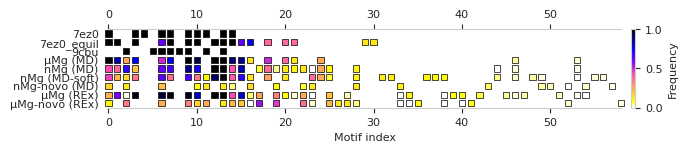

In [ ]:
n_motifs = len(p)
n_sims = len(p.columns)

fig, ax = plt.subplots(figsize=(17.8*cm,4*cm))

ax.invert_yaxis()
ax.grid(None)

p_ = p.iloc[:n_motifs]

#group = p_.index[0][0]
for i, (ndx, row) in enumerate(p_.iterrows()):
    ax.scatter(np.ones(n_sims) * i, np.arange(n_sims), c=row, cmap='gnuplot2_r', edgecolors='k', s=20, marker='s', vmin=0, vmax=1, clip_on=False, linewidths=0.5)
    #if ndx[0] != group:
    #    group = ndx[0]
    #    ax.axvline(i-0.5, ls='dashed', color='lightgray', lw=1)

ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
ax.spines[['left', 'right']].set_visible(False)
ax.set_yticks(range(n_sims), p.columns)
#ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)

ax.set_xlabel('Motif index')
ax.set_xlim(0, n_motifs-1)
ax.set_ylim(n_sims-0.5, -0.5)

cax = plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax, pad=0.02, fraction=0.01, label='Frequency')
plt.tight_layout(h_pad=0)
fig.savefig('figures/motif_analysis.pdf')

In [30]:
# Vertical layout

# n_motifs = 40
# n_sims = len(p.columns)

# fig, ax = plt.subplots(figsize=(8.7*cm, 25*cm))

# ax.invert_yaxis()
# ax.grid(None)

# p_ = p.iloc[:n_motifs]

# group = p_.index[0][0]
# for i, (ndx, row) in enumerate(p_.iterrows()):
#     ax.scatter(np.arange(n_sims), np.ones(n_sims) * i, c=row, cmap='gnuplot2_r', edgecolors='k', s=80, marker='s', vmin=0, vmax=1)
#     if ndx[0] != group:
#         group = ndx[0]
#         ax.axhline(i-0.5, ls='dashed', color='lightgray')

# ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
# ax.set_xticks(range(n_sims), p.columns, rotation=45, ha='left')
# #ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)


# from matplotlib.cm import ScalarMappable
# from matplotlib.colors import Normalize
# cax = plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax, pad=0.01, label='Frequency', orientation='horizontal')

# fig.savefig('figures/motif_analysis.pdf')

## Ion counting

In [133]:
compute = True
if compute:
    results = []

    methods = ['replex', 'plain_md']
    systems = ['7ez0', '7ez0_noion', '7ez0_nomg']
    forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
    replicates = range(2)
    replicas = range(8)

    radius = 40  # Å
    names = ['OW', 'MG', 'NA', 'CL']

    for method, sys, ff, replicate, rep in itertools.product(methods, systems, forcefields, replicates, replicas):
        path = PROJECT_DIR / f'{method}/{sys}/{ff}/replicate{replicate}/rep{rep+replicate*8:02d}'
        if not path.exists():
            continue
        
        u = mda.Universe(path / 'input.gro', path / 'run.xtc')

        if method == 'replex':
            reptemp = read_plumed(path / f'bias.COLVAR.{rep}')['bias.index'].astype(int)
            frames = (reptemp == 0).to_numpy()[::10]
            assert len(frames) == len(u.trajectory)
        else:
            frames = np.ones(len(u.trajectory), dtype=bool)
        sel = np.zeros(len(u.trajectory), dtype=bool)
        sel[::10] = True
        frames = frames & sel

        bulk_sels = {
            name: u.select_atoms(f"name {name}").select_atoms(f"not around {radius} global name P", updating=True)
            for name in names
        }

        tot_sels = {
            name: u.select_atoms(f"name {name}")
            for name in names
        }

        for ts in tqdm(u.trajectory[frames]):
            for name in names:
                results.append(
                    {
                        'sim': f"{method}_{sys}_{ff}",
                        'replicate': replicate if method == 'replex' else rep,
                        'replica': rep if method == 'replex' else 0,
                        'time': ts.time,
                        'name': name,
                        'n_bulk': len(bulk_sels[name]),
                        'n_tot': len(tot_sels[name]),
                        'volume': ts.volume,  # Å³
                    }
                )
                
    df = pd.DataFrame(results).set_index(['sim', 'time', 'name', 'replicate']).sort_index()
    df['c_bulk'] = 1000 * df['n_bulk'] / df['n_bulk'].loc[:, :, 'OW'] * 55.5
    df.to_csv('ion_count_bulk.csv')
else:
    df = pd.read_csv('ion_count_bulk.csv', na_filter=False)
df


100%|██████████| 31/31 [00:41<00:00,  1.34s/it]
0it [00:00, ?it/s]
100%|██████████| 401/401 [06:59<00:00,  1.05s/it]


replica  n_bulk  n_tot  \
sim                         time     name replicate                           
plain_md_7ez0_mMg_tip3p     0.0      CL   0                0      28     91   
                                          1                0      32     91   
                                          2                0      34     91   
                                          3                0      39     91   
                                          4                0      27     91   
...                                                      ...     ...    ...   
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1                6       2    178   
                                     NA   0                3      20    121   
                                          1                6      20    121   
                                     OW   0                3   17043  85656   
                                          1                6   17184  85656   

                                                           volume  \
sim                         time     name replicate                 
plain_md_7ez0_mMg_tip3p     0.0      CL   0          2.704782e+06   
                                          1          2.698821e+06   
                                          2          2.700061e+06   
                                          3          2.697269e+06   
                                          4          2.702006e+06   
...                                                           ...   
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1          2.703253e+06   
                                     NA   0          2.700709e+06   
                                          1          2.703253e+06   
                                     OW   0          2.700709e+06   
                                          1          2.703253e+06   

                                                           c_bulk  
sim                         time     name replicate                
plain_md_7ez0_mMg_tip3p     0.0      CL   0             96.569724  
                                          1            109.656705  
                                          2            118.033402  
                                          3            135.662802  
                                          4             88.271678  
...                                                           ...  
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1              6.459497  
                                     NA   0             65.129379  
                                          1             64.594972  
                                     OW   0          55500.000000  
                                          1          55500.000000  

[92976 rows x 5 columns]

In [136]:

df.reset_index()

,sim,time,name,replicate,replica,n_bulk,n_tot,volume,c_bulk
0,plain_md_7ez0_mMg_tip3p,0.0,CL,0,0,28,91,2.704782e+06,96.569724
1,plain_md_7ez0_mMg_tip3p,0.0,CL,1,0,32,91,2.698821e+06,109.656705
2,plain_md_7ez0_mMg_tip3p,0.0,CL,2,0,34,91,2.700061e+06,118.033402
3,plain_md_7ez0_mMg_tip3p,0.0,CL,3,0,39,91,2.697269e+06,135.662802
4,plain_md_7ez0_mMg_tip3p,0.0,CL,4,0,27,91,2.702006e+06,88.271678
...,...,...,...,...,...,...,...,...,...
92971,replex_7ez0_noion_mMg_tip3p,200000.0,MG,1,6,2,178,2.703253e+06,6.459497
92972,replex_7ez0_noion_mMg_tip3p,200000.0,NA,0,3,20,121,2.700709e+06,65.129379
92973,replex_7ez0_noion_mMg_tip3p,200000.0,NA,1,6,20,121,2.703253e+06,64.594972
92974,replex_7ez0_noion_mMg_tip3p,200000.0,OW,0,3,17043,85656,2.700709e+06,55500.000000


In [138]:
res = df.reset_index()
res = res.loc[res['time'] / 1000 > res['sim'].map(simstart)]
res = res.groupby(['name', 'sim', 'replicate', 'replica']).agg(['mean', 'size'])['c_bulk']
res['weight'] = res['size'] / res['size'].groupby(['name', 'sim']).sum()
res = pd.DataFrame({
    'mean': res.groupby(['name', 'sim']).apply(lambda x: np.average(x['mean'], weights=x['weight'])),
    'ci': res.groupby(['name', 'sim']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['weight']).confidence_interval),
})
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])
res

mean  \
name sim                                           
CL   plain_md_7ez0_mMg_tip3p           71.521209   
     plain_md_7ez0_nMg_tip3p           71.392098   
     plain_md_7ez0_nMg_tip3p_soft      71.550890   
     plain_md_7ez0_noion_nMg_tip3p     71.217002   
     plain_md_7ez0_nomg_mMg_tip3p      62.425751   
     replex_7ez0_mMg_tip3p             71.210789   
     replex_7ez0_noion_mMg_tip3p       70.032808   
MG   plain_md_7ez0_mMg_tip3p           12.003947   
     plain_md_7ez0_nMg_tip3p           12.688453   
     plain_md_7ez0_nMg_tip3p_soft      12.293085   
     plain_md_7ez0_noion_nMg_tip3p     12.958638   
     plain_md_7ez0_nomg_mMg_tip3p       0.000000   
     replex_7ez0_mMg_tip3p             10.855885   
     replex_7ez0_noion_mMg_tip3p       12.373976   
NA   plain_md_7ez0_mMg_tip3p           50.231832   
     plain_md_7ez0_nMg_tip3p           49.134052   
     plain_md_7ez0_nMg_tip3p_soft      49.516129   
     plain_md_7ez0_noion_nMg_tip3p     47.722362   
     plain_md_7ez0_nomg_mMg_tip3p      71.064944   
     replex_7ez0_mMg_tip3p             51.571731   
     replex_7ez0_noion_mMg_tip3p       49.526560   
OW   plain_md_7ez0_mMg_tip3p        55500.000000   
     plain_md_7ez0_nMg_tip3p        55500.000000   
     plain_md_7ez0_nMg_tip3p_soft   55500.000000   
     plain_md_7ez0_noion_nMg_tip3p  55500.000000   
     plain_md_7ez0_nomg_mMg_tip3p   55500.000000   
     replex_7ez0_mMg_tip3p          55500.000000   
     replex_7ez0_noion_mMg_tip3p    55500.000000   

                                                                          ci  \
name sim                                                                       
CL   plain_md_7ez0_mMg_tip3p          (71.34397054380824, 71.70729696252651)   
     plain_md_7ez0_nMg_tip3p          (70.92616356990834, 71.75387400434863)   
     plain_md_7ez0_nMg_tip3p_soft     (71.11863795546542, 71.91228491296297)   
     plain_md_7ez0_noion_nMg_tip3p    (70.80049114948608, 71.62254157906739)   
     plain_md_7ez0_nomg_mMg_tip3p     (61.83882146438993, 63.36323729583779)   
     replex_7ez0_mMg_tip3p            (69.97026517791882, 72.27467226165025)   
     replex_7ez0_noion_mMg_tip3p      (68.60423542023474, 71.80404421350657)   
MG   plain_md_7ez0_mMg_tip3p        (11.539106212075149, 12.366039737974294)   
     plain_md_7ez0_nMg_tip3p        (12.448902699941202, 13.010861834229305)   
     plain_md_7ez0_nMg_tip3p_soft    (12.09087368078853, 12.499438936496894)   
     plain_md_7ez0_noion_nMg_tip3p    (12.62339099836779, 13.33362645555694)   
     plain_md_7ez0_nomg_mMg_tip3p                                 (0.0, 0.0)   
     replex_7ez0_mMg_tip3p          (10.481081976154526, 11.277470591629873)   
     replex_7ez0_noion_mMg_tip3p     (11.422335790476463, 13.54064165865791)   
NA   plain_md_7ez0_mMg_tip3p        (49.135460515166535, 51.194781926591254)   
     plain_md_7ez0_nMg_tip3p         (48.25099952084289, 49.876391845938436)   
     plain_md_7ez0_nMg_tip3p_soft   (48.889617158688885, 50.141170029356104)   
     plain_md_7ez0_noion_nMg_tip3p   (46.767109758308315, 48.45100440346571)   
     plain_md_7ez0_nomg_mMg_tip3p     (70.51670946667299, 71.61745919204127)   
     replex_7ez0_mMg_tip3p            (50.33614760528294, 52.59860117803925)   
     replex_7ez0_noion_mMg_tip3p      (48.38503902275534, 51.01406019542781)   
OW   plain_md_7ez0_mMg_tip3p        (55499.999999999985, 55500.000000000015)   
     plain_md_7ez0_nMg_tip3p         (55499.99999999999, 55500.000000000015)   
     plain_md_7ez0_nMg_tip3p_soft     (55499.99999999999, 55500.00000000001)   
     plain_md_7ez0_noion_nMg_tip3p   (55499.99999999999, 55500.000000000015)   
     plain_md_7ez0_nomg_mMg_tip3p    (55499.99999999999, 55500.000000000015)   
     replex_7ez0_mMg_tip3p          (55499.999999999985, 55500.000000000015)   
     replex_7ez0_noion_mMg_tip3p    (55499.999999999985, 55500.000000000015)   

                                            p025          p095  
name sim         

/tmp/ipykernel_2949/2312705355.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2949/2312705355.py:41: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


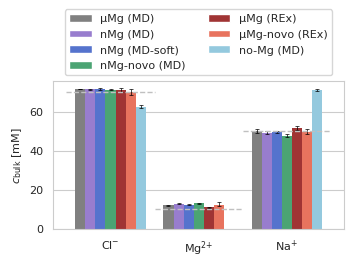

In [139]:
target_cbulk = {
    'CL': 70,
    'MG': 10,
    'NA': 50,
}

fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

data = res.query('name != "OW"').rename(index=simlabels).reset_index()
data['sim'] = data['sim'].astype(CategoricalDtype(categories=simlabels.values(), ordered=True)).cat.remove_unused_categories()

ax = sns.barplot(
    data=data,
    x='name',
    y='mean',
    hue='sim',
    palette=labelcolors,
    ax=ax,
    linestyle='none',
)

for i, (sim, group) in enumerate(data.groupby('sim')):
    container = ax.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
    ax.errorbar(
        x=x_coords,
        y=group['mean'],
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )

for i, (name, group) in enumerate(data.groupby('name')):
    ax.hlines(target_cbulk[name], -0.5 + i, 0.5 + i,  ls='dashed', lw=1, color='silver', zorder=+10)
plt.legend(ncol=2, title=None, loc='lower center', bbox_to_anchor=(0.5, 1))

ax.set_xticklabels([
    ionlabels[t.get_text()] for t in ax.get_xticklabels()
])

ax.set_ylabel(f'$c_\mathrm{{bulk}}$ [mM]')
ax.set_xlabel(None)
fig.savefig(f'figures/bulk_conc.pdf')

In [140]:
df['n_excess'] = df['n_tot'] - 1e-3 * df['c_bulk'] * 1e-27 * df['volume'] * Avogadro

In [141]:
df

replica  n_bulk  n_tot  \
sim                         time     name replicate                           
plain_md_7ez0_mMg_tip3p     0.0      CL   0                0      28     91   
                                          1                0      32     91   
                                          2                0      34     91   
                                          3                0      39     91   
                                          4                0      27     91   
...                                                      ...     ...    ...   
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1                6       2    178   
                                     NA   0                3      20    121   
                                          1                6      20    121   
                                     OW   0                3   17043  85656   
                                          1                6   17184  85656   

                                                           volume  \
sim                         time     name replicate                 
plain_md_7ez0_mMg_tip3p     0.0      CL   0          2.704782e+06   
                                          1          2.698821e+06   
                                          2          2.700061e+06   
                                          3          2.697269e+06   
                                          4          2.702006e+06   
...                                                           ...   
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1          2.703253e+06   
                                     NA   0          2.700709e+06   
                                          1          2.703253e+06   
                                     OW   0          2.700709e+06   
                                          1          2.703253e+06   

                                                           c_bulk     n_excess  
sim                         time     name replicate                             
plain_md_7ez0_mMg_tip3p     0.0      CL   0             96.569724   -66.298324  
                                          1            109.656705   -87.221537  
                                          2            118.033402  -100.924075  
                                          3            135.662802  -129.361621  
                                          4             88.271678   -52.634441  
...                                                           ...          ...  
replex_7ez0_noion_mMg_tip3p 200000.0 MG   1              6.459497   167.484344  
                                     NA   0             65.129379    15.073240  
                                          1             64.594972    15.843440  
                                     OW   0          55500.000000 -4609.488345  
                                          1          55500.000000 -4694.516166  

[92976 rows x 6 columns]

In [142]:
out

mean  size
name sim                         replicate replica                  
ztot plain_md_7ez0_mMg_tip3p     0         0        377.139527   900
                                 1         0        377.219008   900
                                 2         0        377.744706   900
                                 3         0        377.623681   900
                                 4         0        376.758974   900
...                                                        ...   ...
     replex_7ez0_noion_mMg_tip3p 1         2        373.263779    56
                                           3        375.672681     6
                                           5        378.545112    70
                                           6        374.003312    96
                                           7        375.348949    32

[68 rows x 2 columns]

In [144]:
res = df.reset_index()
res = res.loc[res['time'] / 1000 > res['sim'].map(simstart)]
res = res.groupby(['name', 'sim', 'replicate', 'replica']).agg(['mean', 'size'])['n_excess']
out = pd.concat([2*res.loc['MG'] + res.loc['NA'] - res.loc['CL']], keys=['ztot'], names=['name'])
res = pd.concat([res, out])
res['weight'] = res['size'] / res['size'].groupby(['name', 'sim']).sum()
res = pd.DataFrame({
    'mean': res.groupby(['name', 'sim']).apply(lambda x: np.average(x['mean'], weights=x['weight'])),
    'ci': res.groupby(['name', 'sim']).apply(lambda x: 
        bayesian_bootstrap(x['mean'], np.average, weights=x['weight']).confidence_interval),
})
res['p025'] = res['ci'].map(lambda x: x[0])
res['p095'] = res['ci'].map(lambda x: x[1])
res.round(2)

mean  \
name sim                                      
CL   plain_md_7ez0_mMg_tip3p         -25.32   
     plain_md_7ez0_nMg_tip3p         -25.12   
     plain_md_7ez0_nMg_tip3p_soft    -25.39   
     plain_md_7ez0_noion_nMg_tip3p   -24.73   
     plain_md_7ez0_nomg_mMg_tip3p    -34.43   
     replex_7ez0_mMg_tip3p           -24.85   
     replex_7ez0_noion_mMg_tip3p     -22.84   
MG   plain_md_7ez0_mMg_tip3p         158.48   
     plain_md_7ez0_nMg_tip3p         157.36   
     plain_md_7ez0_nMg_tip3p_soft    158.00   
     plain_md_7ez0_noion_nMg_tip3p   156.94   
     plain_md_7ez0_nomg_mMg_tip3p      0.00   
     replex_7ez0_mMg_tip3p           160.34   
     replex_7ez0_noion_mMg_tip3p     157.89   
NA   plain_md_7ez0_mMg_tip3p          39.31   
     plain_md_7ez0_nMg_tip3p          41.08   
     plain_md_7ez0_nMg_tip3p_soft     40.45   
     plain_md_7ez0_noion_nMg_tip3p    43.45   
     plain_md_7ez0_nomg_mMg_tip3p    337.53   
     replex_7ez0_mMg_tip3p            37.10   
     replex_7ez0_noion_mMg_tip3p      40.49   
OW   plain_md_7ez0_mMg_tip3p       -4532.22   
     plain_md_7ez0_nMg_tip3p       -4540.05   
     plain_md_7ez0_nMg_tip3p_soft  -4553.77   
     plain_md_7ez0_noion_nMg_tip3p -4532.83   
     plain_md_7ez0_nomg_mMg_tip3p  -4653.78   
     replex_7ez0_mMg_tip3p         -4560.86   
     replex_7ez0_noion_mMg_tip3p   -4562.13   
ztot plain_md_7ez0_mMg_tip3p         381.58   
     plain_md_7ez0_nMg_tip3p         380.93   
     plain_md_7ez0_nMg_tip3p_soft    381.85   
     plain_md_7ez0_noion_nMg_tip3p   382.06   
     plain_md_7ez0_nomg_mMg_tip3p    371.96   
     replex_7ez0_mMg_tip3p           382.62   
     replex_7ez0_noion_mMg_tip3p     379.11   

                                                                            ci  \
name sim                                                                         
CL   plain_md_7ez0_mMg_tip3p         (-25.638307050155863, -25.03453415450252)   
     plain_md_7ez0_nMg_tip3p        (-25.662988834491205, -24.450618730603306)   
     plain_md_7ez0_nMg_tip3p_soft       (-26.17614669270934, -24.738792460152)   
     plain_md_7ez0_noion_nMg_tip3p  (-25.390040703123162, -24.085558765545205)   
     plain_md_7ez0_nomg_mMg_tip3p   (-35.922979934017576, -33.533597414389554)   
     replex_7ez0_mMg_tip3p          (-26.884254535106415, -23.230474964444653)   
     replex_7ez0_noion_mMg_tip3p     (-25.94169494539045, -20.858649391661064)   
MG   plain_md_7ez0_mMg_tip3p           (157.8879745154072, 159.06743081976063)   
     plain_md_7ez0_nMg_tip3p          (156.75059723983748, 157.85920721388086)   
     plain_md_7ez0_nMg_tip3p_soft     (157.71832495456005, 158.30523654501644)   
     plain_md_7ez0_noion_nMg_tip3p     (156.2536749735688, 157.57250040412666)   
     plain_md_7ez0_nomg_mMg_tip3p                                   (0.0, 0.0)   
     replex_7ez0_mMg_tip3p            (159.73729408034785, 161.03246938677947)   
     replex_7ez0_noion_mMg_tip3p         (156.19647734171, 159.39117617127368)   
NA   plain_md_7ez0_mMg_tip3p            (37.81879904135861, 41.14370295047285)   
     plain_md_7ez0_nMg_tip3p            (39.88381115667076, 42.18286771460136)   
     plain_md_7ez0_nMg_tip3p_soft       (39.39863031149534, 41.61421941108819)   
     plain_md_7ez0_noion_nMg_tip3p       (42.2834805737694, 45.11557145640583)   
     plain_md_7ez0_nomg_mMg_tip3p         (336.6272552914774, 338.19834907346)   
     replex_7ez0_mMg_tip3p              (35.06981642647393, 39.02738689246675)   
     replex_7ez0_noion_mMg_tip3p       (38.78728148237359, 43.050745071515195)   
OW   plain_md_7ez0_mMg_tip3p         (-4541.7169658317325, -4523.590510694169)   
     plain_md_7ez0_nMg_tip3p           (-4548.007351045313, -4531.79445885985)   
     plain_md_7ez0_nMg_tip3p_soft     (-4556.633428087016, -4551.003545698723)   
     plain_md_7ez0_noion_nMg_tip3p     (-4540.439593083469, -4525.82083867145)   
     plain_md_7ez0_nomg_mMg_tip3p     (-4658.180542434933, -4648.101064051946)   
   

/tmp/ipykernel_2949/502893600.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for i, (sim, group) in enumerate(data.groupby('sim')):
/tmp/ipykernel_2949/502893600.py:32: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([


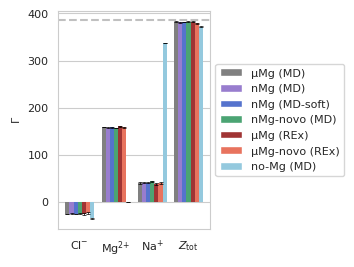

In [145]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

data = res.query('name != "OW"').rename(index=simlabels).reset_index()
data['sim'] = data['sim'].astype(CategoricalDtype(categories=simlabels.values(), ordered=True)).cat.remove_unused_categories()

ax = sns.barplot(
    data=data,
    x='name',
    y='mean',
    hue='sim',
    palette=labelcolors,
    ax=ax,
    linestyle='none',
)

for i, (sim, group) in enumerate(data.groupby('sim')):
    container = ax.containers[i]
    x_coords = [rect.get_x() + rect.get_width() / 2 for rect in container]
    yerr = (group['mean'] - group['p025'], group['p095'] - group['mean'])
    ax.errorbar(
        x=x_coords,
        y=group['mean'],
        yerr=yerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )
ax.axhline(386, color='silver', linestyle='dashed')
plt.legend(title=None, loc='center left', bbox_to_anchor=(1, 0.5))
ax.set_xticklabels([
    ionlabels[t.get_text()] for t in ax.get_xticklabels()
])
ax.set_ylabel(f'$\Gamma$')
ax.set_xlabel(None)
fig.savefig(f'figures/ion_counting.pdf')

In [109]:
# Competition ratio

data = data.set_index(['name', 'sim'])
data.loc['MG']['mean'] / data.loc['NA']['mean']

sim
μMg (MD)          4.109986
nMg (MD)          3.918045
nMg (MD-soft)     4.017986
nMg-novo (MD)     3.685456
no-Mg (MD)        0.000000
μMg (REx)         4.539294
μMg-novo (REx)    4.091903
Name: mean, dtype: float64

### Concentration

- RNA molecule at concentration $[R]$ with $N$ independent sites that can hold either 1 Mg²⁺ or 2 Na⁺
- At equilibrium assume all sites are occupied. The competition is controlled by the exchange at site $i$
  
$$
R_i—\text{Mg} + 2\text{Na⁺} \leftrightarrow R_i—\text{Na₂} + \text{Mg²⁺} 
$$

The equilibrium constant $K$

$$
K = \frac{[R_i\text{Mg}][\text{Na⁺}]²}{[R_i\text{Na₂}][\text{Mg²⁺}]}
$$

The average number of sodium and magnesium per molecule follows

$$
n_\text{Mg} = \frac{N[R_i\text{Mg}]}{[R]} \\
n_\text{Na} = \frac{2N[R_i\text{Na₂}]}{[R]}
$$

Hence

$$
\frac{n_\text{Mg}}{n_\text{Na}} = \frac{[R_i\text{Mg}]}{2[R_i\text{Na₂}]}
$$

$$
K = \frac{2n_\text{Mg}[\text{Na⁺}]²}{n_\text{Na}[\text{Mg²⁺}]}
$$

Let $[\text{Mg²⁺}]_{CC}$ be a fixed concentration of magnesium and $CC$ be the concentration of Na⁺ for which $n_\text{Na} = n_\text{Mg}$.

We deduce

$$
K = \frac{2CC^2}{[\text{Mg²⁺}]_{CC}} = 2αCC
$$

Finally we solve for the ratio

$$
\frac{n_\text{Mg}}{n_\text{Na}} = \frac{[\text{Mg²⁺}]}{2[\text{Na⁺}]^2}K = αCC\frac{[\text{Mg²⁺}]}{[\text{Na⁺}]^2}
$$

In [137]:
α = 17.0 # (https://doi.org/10.1016/j.bpj.2019.08.007)
CC = 102  # mM

print("Required MG/NA ratio to neutralize RNA:", α * CC * target_cbulk['MG'] / target_cbulk['NA']**2)

Required MG/NA ratio to neutralize RNA: 6.936


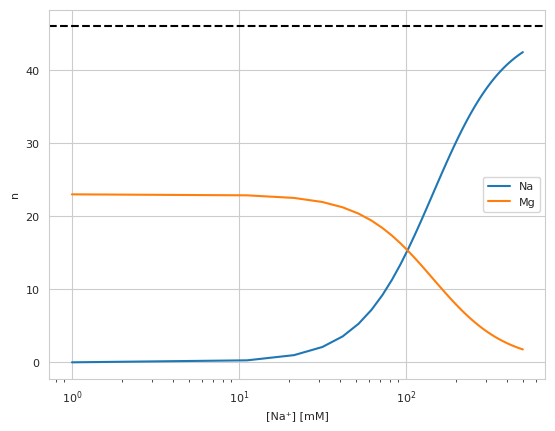

In [151]:
c_range = np.linspace(1, 500)

def get_ratio(c_mg, c_na, α=17, cc=102):
    return α * cc * c_mg / c_na**2

z_tot = 46
plt.plot(c_range, z_tot / (1 + 2 * get_ratio(6, c_range)), label='Na')
plt.plot(c_range, z_tot / (2 + 1 / get_ratio(6, c_range)), label='Mg')
plt.axhline(z_tot, color='black', ls='dashed')
plt.xscale('log')
plt.tick_params(bottom=True, which='minor')
plt.xlabel('[Na⁺] [mM]')
plt.ylabel('n')
plt.legend()


## Density maps

Plot

In [54]:
path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=SparseGrid.load(filename).to_dense().apply_tempfactor(30),
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")
gen_map_avg = gen_maps.groupby(['sim'])[['map', 'weight']].apply(lambda x: np.average(x['map'], weights=x['weight']))

ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")

masks = {
    'RNA + Shell': indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params),
    'RNA': indices_to_mask(voxels_around(rna, 1.8, ref_map.grid_params), ref_map.grid_params),
    'Phosphates': indices_to_mask(voxels_around(rna.select_atoms('name P'), 6, ref_map.grid_params), ref_map.grid_params)
}

masks['Shell'] = masks['RNA + Shell'] & ~masks['RNA']
masks['Phosphate Shell'] = masks['Phosphates'] & ~masks['RNA']

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(


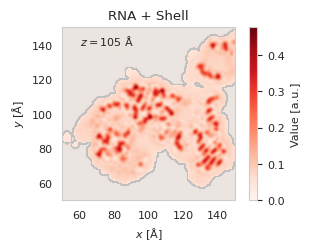

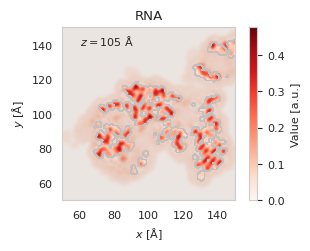

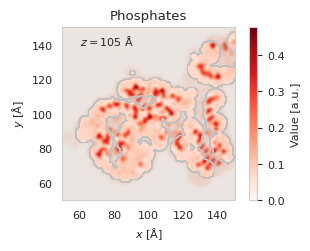

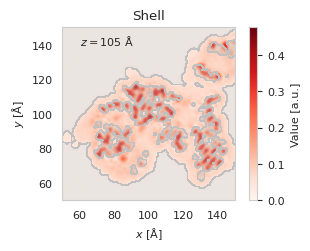

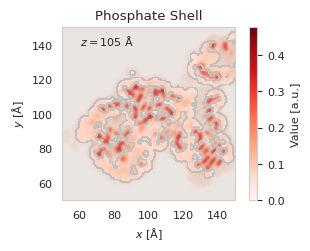

In [107]:

for label, mask in masks.items():
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    plt.rcParams['hatch.color'] = 'silver'
    im = plot_map_slice(gen_map_avg.iloc[0], cmap='Reds', interpolation='bicubic')
    hatches = plot_map_slice(Grid(mask, edges=gen_map_avg.iloc[0].edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True)
    hatches.set_edgecolor('silver')
    hatches.set_linewidth(0.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.05, label='Value [a.u.]')
    ax.set_xlim(50, 150)
    ax.set_ylim(50, 150)
    plt.tight_layout()
    depth = np.median(gen_map_avg.iloc[0].edges[-1])
    ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
    ax.set_xlabel("$x$ [Å]")
    ax.set_ylabel("$y$ [Å]")
    _label = ''.join(c.lower() for c in label if c.isalnum())
    ax.set_title(label)
    plt.tight_layout()
    ax.grid(False)
    fig.savefig(f"figures/gen_map_{_label}.pdf")

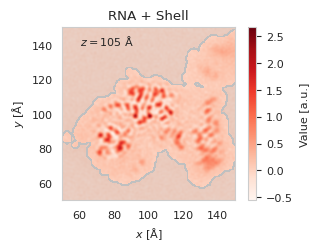

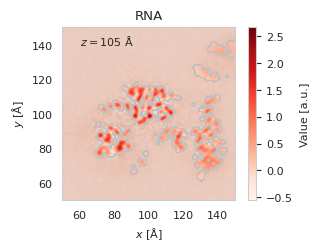

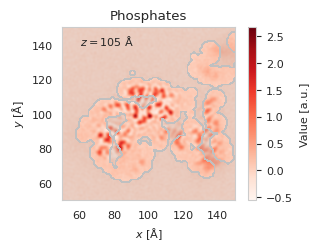

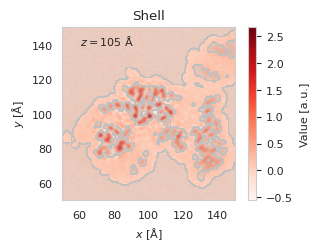

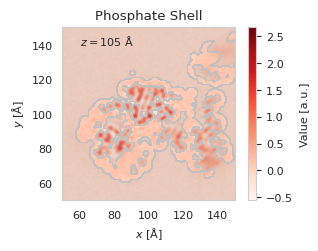

In [108]:
for label, mask in masks.items():
    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

    plt.rcParams['hatch.color'] = 'silver'
    im = plot_map_slice(ref_map, cmap='Reds', interpolation='bicubic')
    hatches = plot_map_slice(Grid(mask, edges=ref_map.edges), func='contourf', colors=[('silver', 0.3), 'none'], corner_mask=True)
    hatches.set_edgecolor('silver')
    hatches.set_linewidth(0.5)
    cbar = plt.colorbar(im, ax=ax, fraction=0.05, label='Value [a.u.]')
    ax.set_xlim(50, 150)
    ax.set_ylim(50, 150)
    plt.tight_layout()
    depth = np.median(ref_map.edges[-1])
    ax.text(0.1, 0.9, f"$z = {depth:.0f}$ Å", transform=ax.transAxes)
    ax.set_xlabel("$x$ [Å]")
    ax.set_ylabel("$y$ [Å]")
    _label = ''.join(c.lower() for c in label if c.isalnum())
    ax.set_title(label)
    ax.grid(False)
    plt.tight_layout()
    fig.savefig(f"figures/ref_map_{_label}.pdf")

### Determine best B-Factor

In [55]:
path = PROJECT_DIR / "density"

data = []
for filename in path.glob("*/all/replicate?_rep??.pkl"):
    weight_file = filename.with_stem(filename.stem + "_weight").with_suffix(".txt")
    if weight_file.exists():
        with open(weight_file, "r") as f:
            weight = float(f.read())
    else:
        weight = 1

    data.append(
        dict(
            sim=filename.parent.parent.name,
            block=filename.stem,
            filename=str(filename),
            map=SparseGrid.load(filename),
            weight=weight,
        )
    )
gen_maps = pd.DataFrame(data)
gen_maps["weight"] /= gen_maps.groupby("sim")["weight"].transform("sum")
gen_map_avg = gen_maps.groupby(['sim'])[['map', 'weight']].apply(lambda x: np.average(x['map'], weights=x['weight']).to_dense())

ref_map = 0.5 * (Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_A.mrc") + Grid(PROJECT_DIR / "density/emd_42499_Con2-2.2A_half_B.mrc"))
rna = mda.Universe(PROJECT_DIR / "structures/9CBU_fixed.pdb").select_atoms("nucleic and not type H and not (resid 22 and name P OP1 OP2)")

cc_mask = indices_to_mask(voxels_around(rna, 6, ref_map.grid_params), ref_map.grid_params)

tempfactors = np.linspace(0, 100, 10+1)

ref_data = ref_map.grid[cc_mask]

def get_cc(map_, tempfactor):
    return linregress(map_.apply_tempfactor(tempfactor).grid[cc_mask], ref_data).rvalue

results = {
    label: [get_cc(map_, tempfactor) for tempfactor in tqdm(tempfactors)]
    for label, map_ in gen_map_avg.items()
}

/net/sbp/sbpstore2/olanguin/mg_sampling/.venv/lib/python3.11/site-packages/MDAnalysis/coordinates/PDB.py:479: UserWarning: 1 A^3 CRYST1 record, this is usually a placeholder. Unit cell dimensions will be set to None.
  warnings.warn(
100%|██████████| 11/11 [00:22<00:00,  2.09s/it]


Text(0, 0.5, 'Pearson correlation')

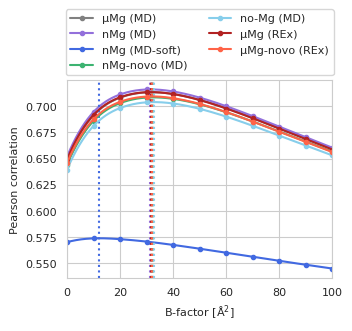

In [35]:
fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))

tempfactor_range = np.linspace(0, 100, 1001)

best_tempfactor = {}
handles, labels = [], []
for sim, cc in results.items():
    marks, = ax.plot(tempfactors, cc, marker='.', ls='none', color=simcolors[sim])
    f = interp1d(tempfactors, cc, kind='cubic')
    cc_interp = f(tempfactor_range)
    line, = ax.plot(tempfactor_range, cc_interp, color=marks.get_color())
    handles.append((marks, line))
    best_tempfactor[sim] = tempfactor_range[np.argmax(cc_interp)]
    ax.axvline(best_tempfactor[sim], color=line.get_color(), ls='dotted')
    labels.append(simlabels[sim])

ax.legend(handles, labels, title=None, loc='lower center', bbox_to_anchor=(0.5, 1), ncol=2)
ax.set_xlim(0, 100)
ax.set_xlabel("B-factor [Å$^2$]")
ax.set_ylabel("Pearson correlation")

In [36]:
pd.Series(best_tempfactor)

plain_md_7ez0_mMg_tip3p          31.9
plain_md_7ez0_nMg_tip3p          31.4
plain_md_7ez0_nMg_tip3p_soft     12.2
plain_md_7ez0_noion_nMg_tip3p    32.5
plain_md_7ez0_nomg_mMg_tip3p     32.7
replex_7ez0_mMg_tip3p            31.6
replex_7ez0_noion_mMg_tip3p      32.0
dtype: float64

### CC

In [57]:
results = []

for k, mask in masks.items():
    for sim, group in tqdm(gen_maps.groupby("sim")[["map", "weight"]]):
        ref_data = ref_map.grid[mask]
        def statistic(maps, weights=None):
            return linregress(
                np.average(maps, weights=weights),
                ref_data,
            ).rvalue
        mapsA = group["map"].apply(lambda x: x.to_dense().grid[mask]).to_numpy()
        weightsA = group["weight"].to_numpy()
        mapA = np.average(mapsA, weights=weightsA, axis=0)
        cc = linregress(
            mapA,
            ref_data,
        ).rvalue

        cc_low, cc_high = bayesian_bootstrap(
            mapsA,
            statistic,
            weights=weightsA,
            n_resamples=200,
            confidence_level=0.99,
        ).confidence_interval

        results.append(
            {
                "sim": sim,
                "mask": k,
                "cc": cc,
                "cc_low": cc_low,
                "cc_high": cc_high,
            }
        )

100%|██████████| 7/7 [00:08<00:00,  1.15s/it]


In [58]:
res = pd.DataFrame(results)
res

,sim,mask,cc,cc_low,cc_high
0,plain_md_7ez0_mMg_tip3p,RNA + Shell,0.648513,0.641078,0.648958
1,plain_md_7ez0_nMg_tip3p,RNA + Shell,0.651837,0.642135,0.652211
2,plain_md_7ez0_nMg_tip3p_soft,RNA + Shell,0.570178,0.504408,0.589038
3,plain_md_7ez0_noion_nMg_tip3p,RNA + Shell,0.644065,0.634437,0.644440
4,plain_md_7ez0_nomg_mMg_tip3p,RNA + Shell,0.639438,0.630285,0.643007
5,replex_7ez0_mMg_tip3p,RNA + Shell,0.649195,0.642365,0.651200
6,replex_7ez0_noion_mMg_tip3p,RNA + Shell,0.645814,0.640043,0.647178
7,plain_md_7ez0_mMg_tip3p,RNA,0.552288,0.544510,0.553202
8,plain_md_7ez0_nMg_tip3p,RNA,0.554650,0.546002,0.555310
9,plain_md_7ez0_nMg_tip3p_soft,RNA,0.427718,0.355579,0.456064


### P-values

In [59]:
compute = False

if compute:
    results = []

    for k, mask in masks.items():
        for (simA, groupA), (simB, groupB) in tqdm(itertools.combinations_with_replacement(gen_maps.groupby("sim")[["map", "weight"]], 2)):
            ref_data = ref_map.grid[mask]

            mapsA = groupA["map"].apply(lambda x: x.grid[mask]).to_numpy()
            nA = len(mapsA)
            weightsA = groupA["weight"].to_numpy()
            mapsB = groupB["map"].apply(lambda x: x.grid[mask]).to_numpy()
            nB = len(mapsB)
            weightsB = groupB["weight"].to_numpy()

            def statistic(maps, weights=None):
                ccA = linregress(
                    np.average(maps[:nA], weights=weights[:nA]),
                    ref_data,
                ).rvalue
                ccB = linregress(
                    np.average(maps[nA:], weights=weights[nA:]),
                    ref_data,
                ).rvalue
                return float(ccA > ccB)

            p_value = bayesian_bootstrap(
                np.concatenate([mapsA, mapsB]),
                statistic,
                weights=np.concatenate([weightsA, weightsB]),
                n_resamples=1000,
            ).bootstrap_distribution.mean()

            results.append(
                {
                    "simA": simA,
                    "simB": simB,
                    "mask": k,
                    "p_value": p_value,
                }
            )
    
    df = pd.DataFrame(results)
    df.to_csv('cc_p_values.csv')
else:
    df = pd.read_csv('cc_p_values.csv')
p_values = df.set_index(['simA', 'simB', 'mask']).rename(index=simlabels)

In [60]:
p_values = p_values.groupby(['simA', 'simB', 'mask'])['p_value'].mean()

In [61]:
p_values

simA            simB            mask           
nMg (MD)        nMg (MD)        Phosphate Shell    0.499333
                                Phosphates         0.499500
                                RNA                0.502000
                                RNA + Shell        0.503833
                                Shell              0.497000
                                                     ...   
μMg-novo (REx)  μMg-novo (REx)  Phosphate Shell    0.511000
                                Phosphates         0.494000
                                RNA                0.479000
                                RNA + Shell        0.483000
                                Shell              0.472000
Name: p_value, Length: 245, dtype: float64

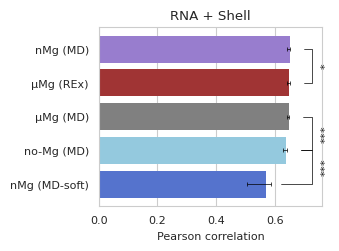

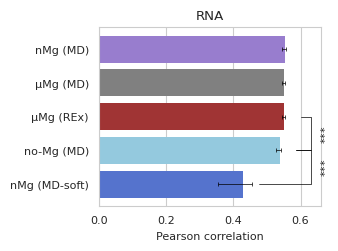

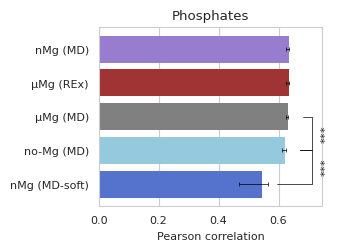

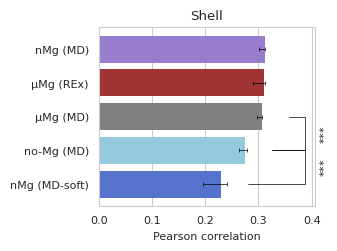

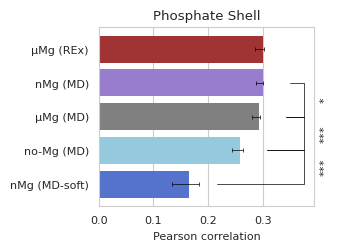

In [62]:
for label in masks.keys():

    group = res.query('mask == @label').loc[res['sim'].isin(simselection)]
    group = group.sort_values('cc', ascending=False)
    group['sim'] = group['sim'].map(simlabels)
    group['sim'] = group['sim'].astype(CategoricalDtype(categories=group['sim'], ordered=True))

    fig, ax = plt.subplots(figsize=(8.7*cm, 6.5*cm))
    ax = sns.barplot(
        data=group,
        x='cc',
        y='sim',
        hue='sim',
        palette=labelcolors,
        ax=ax,
        linestyle='none',
    )

    xerr = (group['cc'] - group['cc_low'], group['cc_high'] - group['cc'])
    ax.errorbar(
        x=group['cc'],
        y=group['sim'],
        xerr=xerr,
        ls='none',
        c='black',
        capsize=1.5,
        elinewidth=0.5,
        capthick=0.5,
    )
    h = 0.05
    x_max = group['cc'].max() + 1.5*h
    for (i, simA), (j, simB) in itertools.pairwise(enumerate(group['sim'])):
        significance = 0
        if p_values.loc[simB, simA, label] < 0.05:
            significance += 1
        if p_values.loc[simB, simA, label] < 0.01:
            significance += 1
        if p_values.loc[simB, simA, label] < 0.001:
            significance += 1
        if significance > 0:
            x1 = group.iloc[i]['cc']
            x2 = group.iloc[j]['cc']
            y1 = i
            y2 = j
            ax.plot([x1+h, x_max, x_max, x2+h], [y1, y1, y2, y2], color='black', lw=0.5)
            ax.text(x_max+0.5*h, 0.5*(y1+y2), ''.join(significance * [r'$*$']), va='center', ha='left', rotation=90)

    ax.set_title(label)
    ax.set_ylabel(None)
    ax.set_xlabel('Pearson correlation')
    plt.tight_layout()
    _label = ''.join(c.lower() for c in label if c.isalnum())
    fig.savefig(f'figures/cross_correlation_{_label}{suffix}.pdf')

In [94]:
p_values.loc['nMg (MD)', 'μMg (REx)']

mask
Phosphate Shell    0.470667
Phosphates         0.900167
RNA                0.972167
RNA + Shell        0.974833
Shell              0.871833
Name: p_value, dtype: float64